# Projeto 5 · Avaliação de classificadores e dados do dashboard
**Mapeamento e Previsão de Pontos Críticos de Sinistros de Trânsito no Recife**

Fonte: chamados da CTTU, arquivos oficiais de 2015–2024, obtidos em **04/11/2026**. Este notebook executa a preparação, o painel bairro-mês, dois classificadores simples e dois baselines, a avaliação temporal, as figuras e a exportação dos dados que alimentam o dashboard.

**Unidade da classificação:** bairro-mês. **Classe positiva:** volume mensal ≥ percentil 75 das contagens do treino, arredondado para cima, com mínimo de um chamado. Neste snapshot, o corte é **3 chamados**. Esse rótulo é relativo ao histórico de treino; não significa maior gravidade ou risco individual.

Execute as células em ordem no Google Colab. O notebook é autocontido e tenta baixar os arquivos oficiais; também aceita o snapshot do ZIP em `dados/brutos`. Os hashes distinguem as versões. Não há dados artificiais na análise.

**Execução verificada:** todas as células foram executadas sequencialmente via IPython em 04/11/2026, com os CSVs reais e saídas capturadas. O kernel Jupyter não iniciou por restrição de sockets neste ambiente. O serviço Google Colab não foi acessado; a compatibilidade foi preparada no código.

In [1]:
import sys,importlib.util,importlib.metadata,subprocess
deps={'numpy':('numpy>=1.26',(1,26)),'pandas':('pandas>=2.2,<3',(2,2)),
      'scipy':('scipy>=1.13',(1,13)),'sklearn':('scikit-learn>=1.5',(1,5)),
      'matplotlib':('matplotlib>=3.9',(3,9)),'requests':('requests>=2.31',(2,31))}
missing=[]
for m,(spec,minimum) in deps.items():
    if importlib.util.find_spec(m) is None:missing.append(spec)
    else:
        dist='scikit-learn' if m=='sklearn' else m
        version=tuple(int(x) for x in importlib.metadata.version(dist).split('.')[:2])
        if version<minimum or (m=='pandas' and version[0]>=3):missing.append(spec)
if missing:subprocess.check_call([sys.executable,'-m','pip','install',*missing])
from pathlib import Path
RAIZ=Path('/content/projeto5_entregas') if Path('/content').exists() else Path.cwd()
RAIZ.mkdir(parents=True,exist_ok=True)
print('Diretório dos arquivos:',RAIZ)

Diretório dos arquivos: /workspace/scratch/b0cc3dc3bfea/entregas_semanais


## 1. Aquisição e proveniência
São dez CSVs, um por ano, mais o cadastro de 94 bairros e a malha oficial. Os arquivos locais do snapshot são reaproveitados e verificados por SHA-256. Se algum download falhar, a análise para com erro explícito. O período de 2015 começa em junho. Não se preenchem anos inexistentes com zeros.

In [2]:
"""Aquisição oficial com cache local e integridade do snapshot disponibilizado."""
from pathlib import Path
from datetime import datetime,timezone
from concurrent.futures import ThreadPoolExecutor
import urllib.request,json,re,hashlib

def obter_dados(root):
    root=Path(root);raw=root/'dados/brutos';raw.mkdir(parents=True,exist_ok=True)
    if (raw/'manifesto_aquisicao.json').exists():
        manifest=json.loads((raw/'manifesto_aquisicao.json').read_text())
        for row in manifest:
            p=raw/f'cttu_{row["ano"]}.csv'
            if p.exists() and row.get('sha256') and hashlib.sha256(p.read_bytes()).hexdigest()!=row['sha256']:
                raise ValueError(f'Hash divergente: {p.name}. Preserve e revise a versão antes de analisar.')
    needed=[raw/f'cttu_{y}.csv' for y in range(2015,2025)]+[raw/'bairros_oficiais.csv',raw/'bairros_oficiais.geojson']
    if all(p.exists() and p.stat().st_size>100 for p in needed):
        print('Snapshot local completo: dez anos, cadastro e malha oficial.');return
    portal='https://dados.recife.pe.gov.br'
    def catalogo(dataset):
        j=json.load(urllib.request.urlopen(portal+'/api/3/action/package_show?id='+dataset,timeout=45))
        if not j.get('success'):raise RuntimeError('CKAN sem sucesso')
        return j
    j=catalogo('acidentes-de-transito-com-e-sem-vitimas');(raw/'catalogo_cttu.json').write_text(json.dumps(j,ensure_ascii=False,indent=2))
    resources=[]
    for rec in j['result']['resources']:
        m=re.search(r'20(?:1[5-9]|2[0-4])',rec.get('name',''))
        if m and rec.get('format','').lower()=='csv':resources.append((int(m[0]),rec))
    if len(resources)!=10:raise RuntimeError('Catálogo não retornou exatamente dez anos; revisar os recursos.')
    def download(item):
        year,rec=item;p=raw/f'cttu_{year}.csv'
        if not p.exists():
            req=urllib.request.Request(rec['url'],headers={'Cache-Control':'no-cache','User-Agent':'Projeto5-Academico'})
            b=urllib.request.urlopen(req,timeout=90).read()
            if len(b)<100 or b.lstrip().startswith(b'<'):raise RuntimeError('Download não é CSV: '+str(year))
            p.write_bytes(b)
        b=p.read_bytes();print(year,len(b),'bytes')
        return {'ano':year,'recurso_id':rec['id'],'url':rec['url'],'bytes':len(b),
          'sha256':hashlib.sha256(b).hexdigest(),'obtido_utc':datetime.now(timezone.utc).isoformat(),'resultado':'obtido'}
    with ThreadPoolExecutor(max_workers=5) as ex:manifest=list(ex.map(download,resources))
    (raw/'manifesto_aquisicao.json').write_text(json.dumps(manifest,ensure_ascii=False,indent=2))
    j=catalogo('area-urbana');(raw/'catalogo_area_urbana.json').write_text(json.dumps(j,ensure_ascii=False,indent=2))
    ids={'a378d50a-5e55-4956-a28c-13305acfc2b3':'bairros_oficiais.csv','5c67ce14-1799-40c4-a37c-9daa04d1761c':'bairros_oficiais.geojson'}
    for rec in j['result']['resources']:
        if rec['id'] in ids:
            p=raw/ids[rec['id']]
            if not p.exists():p.write_bytes(urllib.request.urlopen(rec['url'],timeout=90).read())
    if not all(p.exists() for p in needed):raise RuntimeError('Aquisição incompleta; nenhum resultado será inventado.')



In [3]:
obter_dados(RAIZ)

Snapshot local completo: dez anos, cadastro e malha oficial.


## 2. Preparação dos registros
Normalizam-se colunas, datas, horários e chaves auxiliares dos bairros. O texto original permanece no CSV bruto. O vínculo territorial é exato após normalização de acentos, caixa e espaços; não há fuzzy matching. Os nomes divergentes são exportados para auditoria.

Um protocolo repetido com conteúdo idêntico seria cópia técnica removível. Conteúdos divergentes e linhas sem protocolo são apenas sinalizados. Nenhuma cópia técnica desse tipo foi removida no snapshot. Todos os status participam da contagem de chamados; não se presume que cada linha seja um acidente único ou confirmado.

Datas ISO têm interpretação separada de datas brasileiras. Datas de outro ano não entram nas séries temporais. Vítimas fatais ausentes nunca são transformadas em zero. O preenchimento do campo não comprova comparabilidade histórica.

In [4]:
"""CTTU 2015-2024: processamento rastreável; não contém dados simulados."""
from pathlib import Path
from datetime import datetime, timezone
from concurrent.futures import ThreadPoolExecutor
import csv, io, json, re, hashlib, unicodedata, platform
import numpy as np
import pandas as pd
import requests
from scipy import stats, optimize
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

PORTAL = 'https://dados.recife.pe.gov.br'
DATASET = 'acidentes-de-transito-com-e-sem-vitimas'
IDS = dict(zip(range(2015,2025), [
 '58816e1f-18bc-4335-82bf-80ff080cb0e5','edc820d6-0f01-4fd2-b8a4-5a8c95f7e743',
 'd364e034-7e00-41a7-b557-0b16c21814e7','a7b72334-9229-4e52-a6cb-8006de4942e3',
 'c9fe4a98-0f61-4e81-9c4b-a22f8dc6f1a2','b2594588-2aa8-42c4-b96d-246102ecde3c',
 '31ee35d9-6f8e-4694-9492-efe96e902b07','c2281788-2e8c-472c-8812-67c4f85e9272',
 'dbb9165a-7539-4fdd-943a-acffe12df3e0','87ac4237-f5f9-44d2-bcf1-927aaa0a2d31']))
BAIRROS_ID='a378d50a-5e55-4956-a28c-13305acfc2b3'

def chave(x):
    if pd.isna(x): return pd.NA
    s=unicodedata.normalize('NFKD',str(x)).encode('ascii','ignore').decode().upper()
    s=' '.join(s.strip().split())
    return s if s else pd.NA

def coluna(x):
    return re.sub(r'[^a-z0-9]+','_',str(chave(x)).lower()).strip('_')

def ler_csv(path):
    blob=Path(path).read_bytes()
    for enc in ['utf-8-sig','cp1252','latin1']:
        try: text=blob.decode(enc)
        except UnicodeDecodeError: continue
        head=text.splitlines()[0]
        sep=max([';',',','\t','|'],key=head.count)
        # Não ignorar linhas malformadas e não converter silenciosamente NA em zero.
        d=pd.read_csv(io.StringIO(text),sep=sep,dtype='string',keep_default_na=False)
        if len(d.columns)<2: raise ValueError(f'CSV inválido: {path}')
        d.columns=[coluna(c) for c in d.columns]
        if d.columns.duplicated().any(): raise ValueError('Colisões de nomes de colunas')
        d=d.apply(lambda s:s.str.strip()).replace(r'^\s*$|^(?i:NA|N/A|NULL|NAN)$',pd.NA,regex=True)
        return d,enc,sep
    raise ValueError(f'Codificação inválida: {path}')

def preparar(root):
    root=Path(root); bases=[]; inventario=[]; dup=[]
    for ano in IDS:
        path=root/f'dados/brutos/cttu_{ano}.csv'
        if not path.exists(): continue
        d,enc,sep=ler_csv(path); orig=d.columns.tolist(); n=len(d)
        d['ano_origem']=ano; d['arquivo_origem']=path.name
        # Número ordinal do registro de dados; não é linha física se houver CSV multilinha.
        d['registro_origem']=np.arange(1,n+1)
        d['id_rastreio']=str(ano)+':'+d.registro_origem.astype(str)
        d['duplicado_exato']=d.duplicated(subset=[c for c in orig if c!='id'],keep=False)
        if 'protocolo' in d:
            d['protocolo_repetido']=d.protocolo.notna() & d.protocolo.duplicated(keep=False)
        else: d['protocolo_repetido']=False
        # Mesmo protocolo com conteúdo exatamente igual: cópia técnica demonstrável.
        rem=d.duplicated(subset=[c for c in orig if c!='id'],keep='first')
        rem &= d.get('protocolo',pd.Series(pd.NA,index=d.index)).notna()
        d['excluir_copia_tecnica']=rem
        dup.append(d.loc[d.duplicado_exato|d.protocolo_repetido].copy())
        for c in ['data','hora','bairro','situacao','tipo','natureza','natureza_acidente','vitimas','vitimasfatais']:
            if c not in d:d[c]=pd.NA
        # ISO deve preceder a interpretação brasileira: evita trocar mês e dia em ISO.
        s=d.data.astype('string');iso=s.str.match(r'^\d{4}-\d{2}-\d{2}',na=False)
        dt=pd.Series(pd.NaT,index=d.index,dtype='datetime64[ns]')
        dt.loc[iso]=pd.to_datetime(s[iso],format='ISO8601',errors='coerce')
        dt.loc[~iso]=pd.to_datetime(s[~iso],format='mixed',dayfirst=True,errors='coerce')
        d['data_dt']=dt.dt.normalize()
        d['data_valida']=dt.notna() & dt.dt.year.eq(ano)
        d['ano_divergente']=dt.notna() & ~dt.dt.year.eq(ano)
        h=d.hora.astype('string').str.extract(r'^(\d{1,2}):(\d{2})(?::(\d{2})(?:\.\d+)?)?$')
        hh=pd.to_numeric(h[0],errors='coerce'); mm=pd.to_numeric(h[1],errors='coerce'); ss=pd.to_numeric(h[2],errors='coerce').fillna(0)
        d['hora_n']=hh.where(hh.between(0,23)&mm.between(0,59)&ss.between(0,59))
        for c in ['bairro','situacao','tipo','natureza','natureza_acidente']:d[c+'_chave']=d[c].map(chave)
        for c in ['vitimas','vitimasfatais']:
            x=pd.to_numeric(d[c].astype('string').str.replace(',','.',regex=False),errors='coerce')
            d[c+'_n']=x.where(x.ge(0)&x.mod(1).eq(0))
        inventario.append({'ano':ano,'linhas_brutas':n,'copias_tecnicas':int(rem.sum()),
            'encoding':enc,'separador':sep,'sha256':hashlib.sha256(path.read_bytes()).hexdigest(),
            'colunas_originais':json.dumps(orig,ensure_ascii=False)})
        bases.append(d)
    if not bases: return None,{},pd.DataFrame()
    bruto=pd.concat(bases,ignore_index=True,sort=False)
    base=bruto.loc[~bruto.excluir_copia_tecnica].copy()
    t={'inventario':pd.DataFrame(inventario),'duplicidades_auditoria':pd.concat(dup,ignore_index=True)}
    t['qualidade_datas_horas']=base.groupby('ano_origem').agg(linhas=('id_rastreio','size'),
        datas_validas=('data_valida','sum'),ano_divergente=('ano_divergente','sum'),horas_validas=('hora_n','count'))
    t['status']=base.groupby(['ano_origem','situacao_chave'],dropna=False).size().rename('chamados').reset_index()
    aus=[]
    for a,g in bruto.groupby('ano_origem'):
        cols=json.loads(t['inventario'].set_index('ano').loc[a,'colunas_originais'])
        for c in ['data','hora','bairro','situacao','tipo','natureza','natureza_acidente','vitimas','vitimasfatais']:
            aus.append({'ano':a,'campo':c,'existe_na_origem':c in cols,'total':len(g),
              'ausentes':int(g[c].isna().sum()),'pct_ausente':100*g[c].isna().mean()})
    t['ausencias']=pd.DataFrame(aus)
    # Validação estrita contra a relação oficial, sem fuzzy matching nem equivalências inventadas.
    bp=root/'dados/brutos/bairros_oficiais.csv'; nomes=[]
    if bp.exists():
        b,_,_=ler_csv(bp)
        if 'bairro' not in b: raise ValueError('Relação oficial não contém campo bairro')
        nomes=b.bairro.map(chave).dropna().unique().tolist()
        if b.bairro.map(chave).dropna().duplicated().any():raise ValueError('Colisão na relação de bairros')
    base['bairro_validado']=base.bairro_chave.isin(nomes) if nomes else False
    t['bairros_nao_validados']=base.loc[~base.bairro_validado].groupby(['ano_origem','bairro_chave'],dropna=False).size().rename('chamados').reset_index()
    return base,t,bruto


from types import SimpleNamespace
prep=SimpleNamespace(preparar=preparar,ler_csv=ler_csv,chave=chave)

In [5]:
"""Avaliação temporal reproduzível de classificadores de volume de chamados CTTU."""
from pathlib import Path
import json, hashlib, platform, importlib.metadata, shutil, warnings
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (confusion_matrix,accuracy_score,precision_score,recall_score,f1_score,
 roc_auc_score,average_precision_score,roc_curve,precision_recall_curve,balanced_accuracy_score,brier_score_loss)
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt


NUM=['lag1','lag2','lag3','lag6','media3','media6','dp6','tendencia','mes_sin','mes_cos']
NAMES={'dummy':'Majoritária','persistencia':'Persistência','logistica':'Regressão logística','arvore':'Árvore de decisão'}
COLORS={'dummy':'#9BA8B4','persistencia':'#B68445','logistica':'#127F80','arvore':'#476FB3'}

def dump(path,obj):
    Path(path).write_text(json.dumps(obj,ensure_ascii=False,allow_nan=False,separators=(',',':')),encoding='utf-8')

def metrics(y,s,threshold):
    pred=np.asarray(s)>=threshold;tn,fp,fn,tp=confusion_matrix(y,pred,labels=[0,1]).ravel()
    return dict(acuracia=accuracy_score(y,pred),precisao=precision_score(y,pred,zero_division=0),
        recall=recall_score(y,pred,zero_division=0),f1=f1_score(y,pred,zero_division=0),
        acuracia_balanceada=balanced_accuracy_score(y,pred),roc_auc=roc_auc_score(y,s),
        average_precision=average_precision_score(y,s),tn=int(tn),fp=int(fp),fn=int(fn),tp=int(tp),
        n=len(y),positivos=int(np.sum(y)),limiar=float(threshold))

def carregar(root):
    root=Path(root);q=root/'qualidade';q.mkdir(exist_ok=True)
    with warnings.catch_warnings():
        warnings.simplefilter('ignore',FutureWarning);base,t,bruto=prep.preparar(root)
    if base is None or set(base.ano_origem.unique())!=set(range(2015,2025)):
        raise RuntimeError('São necessários os dez CSVs oficiais de 2015-2024; nenhum dado é simulado.')
    for name,tab in t.items():tab.to_csv(q/f'{name}.csv',index=False,encoding='utf-8-sig')
    oficiais,_,_=prep.ler_csv(root/'dados/brutos/bairros_oficiais.csv')
    bairros=oficiais.bairro.map(prep.chave).tolist()
    # Sem equivalências aproximadas: todo vínculo é exato após normalização textual.
    resumo=[]
    for ano,g in base.groupby('ano_origem'):
        resumo.append({'ano':int(ano),'brutos':int((bruto.ano_origem==ano).sum()),'analiticos':len(g),
          'datas_validas':int(g.data_valida.sum()),'datas_invalidas_ou_outro_ano':int((~g.data_valida).sum()),
          'horas_validas':int(g.hora_n.notna().sum()),'bairro_validado':int(g.bairro_validado.sum()),
          'pct_bairro_validado':100*g.bairro_validado.mean(),
          'finalizada':int(g.situacao_chave.eq('FINALIZADA').sum()),
          'pct_excluido_finalizada':100*(1-g.situacao_chave.eq('FINALIZADA').mean()),
          'vitimasfatais_validos':int(g.vitimasfatais_n.notna().sum()),
          'pct_fatal_ausente':100*g.vitimasfatais_n.isna().mean(),
          'primeira_data_valida':str(g.loc[g.data_valida,'data_dt'].min().date()),
          'ultima_data_valida':str(g.loc[g.data_valida,'data_dt'].max().date())})
    qualidade=pd.DataFrame(resumo);qualidade.to_csv(q/'qualidade_por_ano.csv',index=False,encoding='utf-8-sig')
    # As 36 datas do arquivo de 2024 que pertencem a outro ano são preservadas e excluídas só da dimensão temporal.
    base.to_csv(root/'dados/chamados_tratados.csv.gz',index=False,compression='gzip')
    return base,bairros,qualidade



In [6]:
from IPython.display import display,Markdown,Image
base,bairros,qualidade=carregar(RAIZ)
display(qualidade)
print('Registros brutos:',len(base),'| Datas válidas:',int(base.data_valida.sum()))
display(pd.read_csv(RAIZ/'qualidade/bairros_nao_validados.csv').head(25))

Registros brutos: 72255 | Datas válidas: 72219


,ano,brutos,analiticos,datas_validas,datas_invalidas_ou_outro_ano,horas_validas,bairro_validado,pct_bairro_validado,finalizada,pct_excluido_finalizada,vitimasfatais_validos,pct_fatal_ausente,primeira_data_valida,ultima_data_valida
0,2015,7273,7273,7273,0,7273,7100,97.621339,5175,28.846418,0,100.000000,2015-06-01,2015-12-31
1,2016,11263,11263,11263,0,11256,11026,97.895765,8519,24.362958,39,99.653733,2016-01-01,2016-12-31
2,2017,11758,11758,11758,0,11736,11576,98.452118,9224,21.551284,38,99.676816,2017-01-01,2017-12-31
3,2018,11411,11411,11411,0,11393,11213,98.264832,9494,16.799579,27,99.763386,2018-01-01,2018-12-31
4,2019,12062,12062,12062,0,12044,11679,96.824739,10109,16.191345,25,99.792738,2019-01-01,2019-12-31
5,2020,4092,4092,4092,0,4092,3984,97.360704,3496,14.565005,21,99.486804,2020-01-01,2020-12-31
6,2021,2380,2380,2380,0,2380,2338,98.235294,2096,11.932773,2380,0.000000,2021-01-01,2021-12-31
7,2022,2669,2669,2669,0,0,2601,97.452229,2391,10.415886,2669,0.000000,2022-01-01,2022-12-31
8,2023,4032,4032,4032,0,4032,3934,97.569444,3575,11.334325,4032,0.000000,2023-01-01,2023-12-31
9,2024,5315,5315,5279,36,5315,5195,97.742239,4929,7.262465,5315,0.000000,2024-01-01,2024-12-28


,ano_origem,bairro_chave,chamados
0,2015,ALTO SANTA TERESINHA,5
1,2015,BAIRRO DO RECIFE,101
2,2015,JOANA BEZERRA,13
3,2015,MARCELO,1
4,2015,POCO DA PANELA,2
5,2015,SETUBAL,1
6,2015,NaN,50
7,2016,ALTO SANTA TERESINHA,9
8,2016,BAIRRO DO RECIFE,132
9,2016,JOANA BEZERRA,33


## 3. Painel temporal e definição do alvo
O painel inclui os 94 bairros oficiais, mesmo quando têm contagem zero no arquivo. Usam-se dados de 2021–2024 para reduzir a mistura com o regime de registro de maior volume de 2015–2019. Isso não garante estabilidade do processo de captação.

O mês alvo é **t**. Todos os lags e médias móveis usam no máximo **t−1**. Lags: 1, 2, 3 e 6 meses; médias: 3 e 6; dispersão dos seis meses anteriores; diferença lag1−lag3; mês cíclico e bairro. O mês conhecido no calendário não é vazamento. As primeiras seis observações de cada bairro não entram no treino por falta de histórico.

Treino: jul/2021–dez/2022 (1.692 bairro-meses); validação: 2023 (1.128); teste: 2024 (1.128). O corte do alvo usa apenas o treino. Os empates na contagem fazem a classe positiva diferir de exatamente 25% das linhas. Uma data sem chamado no arquivo não comprova ausência de sinistro.

In [7]:
def painel_mensal(base,bairros):
    v=base.loc[base.data_valida & base.bairro_validado].copy()
    v['periodo']=v.data_dt.dt.to_period('M').astype(str)
    idx=pd.MultiIndex.from_product([bairros,pd.period_range('2021-01','2024-12',freq='M').astype(str)],names=['bairro','periodo'])
    c=v.groupby(['bairro_chave','periodo']).size()
    c.index=c.index.set_names(['bairro','periodo'])
    panel=c.reindex(idx,fill_value=0).rename('chamados').reset_index().sort_values(['bairro','periodo'])
    # Meses sem qualquer chamado municipal sugerem falha de cobertura, não milhares de negativos.
    assert panel.groupby('periodo').chamados.sum().gt(0).all(),'Há mês inteiro sem dados: revisar cobertura antes da modelagem.'
    g=panel.groupby('bairro',sort=False)
    for k in [1,2,3,6]:panel[f'lag{k}']=g.chamados.shift(k)
    for k in [3,6]:panel[f'media{k}']=g.chamados.transform(lambda x:x.shift(1).rolling(k).mean())
    panel['dp6']=g.chamados.transform(lambda x:x.shift(1).rolling(6).std(ddof=0))
    panel['tendencia']=panel.lag1-panel.lag3
    month=panel.periodo.str[-2:].astype(int)
    panel['mes_sin']=np.sin(2*np.pi*month/12);panel['mes_cos']=np.cos(2*np.pi*month/12)
    panel=panel.dropna(subset=NUM).copy()
    panel['particao']=np.select([panel.periodo.le('2022-12'),panel.periodo.le('2023-12')],['treino','validacao'],default='teste')
    treino=panel.loc[panel.particao.eq('treino')]
    corte=max(1,int(np.ceil(treino.chamados.quantile(.75))))
    panel['alvo']=(panel.chamados>=corte).astype(int)
    # Verificação independente: feature mais recente é exatamente o mês anterior do mesmo bairro.
    hist=c.to_dict()
    assert all(row.lag1==hist.get((row.bairro,str(pd.Period(row.periodo)-1)),0) for row in panel.itertuples())
    assert panel.loc[panel.particao.eq('treino'),'periodo'].max()<panel.loc[panel.particao.eq('validacao'),'periodo'].min()
    assert panel.loc[panel.particao.eq('validacao'),'periodo'].max()<panel.loc[panel.particao.eq('teste'),'periodo'].min()
    assert not panel.duplicated(['bairro','periodo']).any()
    return panel,corte



In [8]:
painel,corte=painel_mensal(base,bairros)
print('Volume elevado: chamados >=',corte)
display(painel.groupby('particao').agg(n=('alvo','size'),positivos=('alvo','sum'),inicio=('periodo','min'),fim=('periodo','max')))
display(painel.head())

Volume elevado: chamados >= 3


,n,positivos,inicio,fim
particao,,,,
teste,1128,519,2024-01,2024-12
treino,1692,504,2021-07,2022-12
validacao,1128,438,2023-01,2023-12


,bairro,periodo,chamados,lag1,lag2,lag3,lag6,media3,media6,dp6,tendencia,mes_sin,mes_cos,particao,alvo
6,AFLITOS,2021-07,1,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.0,-0.500000,-8.660254e-01,treino,0
7,AFLITOS,2021-08,0,1.0,0.0,0.0,0.0,0.333333,0.166667,0.372678,1.0,-0.866025,-5.000000e-01,treino,0
8,AFLITOS,2021-09,1,0.0,1.0,0.0,0.0,0.333333,0.166667,0.372678,0.0,-1.000000,-1.836970e-16,treino,0
9,AFLITOS,2021-10,0,1.0,0.0,1.0,0.0,0.666667,0.333333,0.471405,0.0,-0.866025,5.000000e-01,treino,0
10,AFLITOS,2021-11,2,0.0,1.0,0.0,0.0,0.333333,0.333333,0.471405,0.0,-0.500000,8.660254e-01,treino,0


## 4. Classificadores simples e baselines
- **Regressão logística:** C=1, escala numérica e one-hot do bairro; transformações ajustadas somente no treino.
- **Árvore de decisão:** profundidade máxima 4 e mínimo de 30 observações por folha.
- **Majoritária:** distribuição a priori do treino; com limiar 0,5, prevê classe regular neste snapshot.
- **Persistência:** usa o volume do mês anterior; o score monotônico lag1/(lag1+corte), com limiar 0,5, equivale a repetir se a contagem anterior atingia o corte. Esse score não é probabilidade calibrada.

Escolhem-se limiares da logística e da árvore em uma grade 0,05–0,95 pelo F1 de **validação**. O modelo entre esses dois é escolhido na mesma validação. Não há busca de hiperparâmetros no teste. O modelo não é reajustado após 2022.

A avaliação em 2024 é de **um passo à frente**, mês a mês, com os meses anteriores já observados; não é uma previsão de doze meses simultânea feita em dezembro de 2023. A disponibilidade operacional e o atraso de atualização da base não são conhecidos: trata-se de um experimento retrospectivo.

In [9]:
def treinar(panel,corte,out):
    out=Path(out);tab=out/'tabelas';tab.mkdir(parents=True,exist_ok=True)
    train=panel[panel.particao.eq('treino')];val=panel[panel.particao.eq('validacao')];test=panel[panel.particao.eq('teste')]
    pre=ColumnTransformer([('numericas',StandardScaler(),NUM),('bairro',OneHotEncoder(handle_unknown='ignore',sparse_output=False),['bairro'])])
    models={'dummy':Pipeline([('pre',pre),('modelo',DummyClassifier(strategy='prior'))]),
      'logistica':Pipeline([('pre',ColumnTransformer([('numericas',StandardScaler(),NUM),('bairro',OneHotEncoder(handle_unknown='ignore',sparse_output=False),['bairro'])])),('modelo',LogisticRegression(C=1,max_iter=2000,random_state=42))]),
      'arvore':Pipeline([('pre',ColumnTransformer([('numericas','passthrough',NUM),('bairro',OneHotEncoder(handle_unknown='ignore',sparse_output=False),['bairro'])])),('modelo',DecisionTreeClassifier(max_depth=4,min_samples_leaf=30,random_state=42))])}
    scores={};limits={};thresholdrows=[]
    for name in ['dummy','persistencia','logistica','arvore']:
        if name=='persistencia':
            sv=val.lag1.to_numpy()/(val.lag1.to_numpy()+corte);st=test.lag1.to_numpy()/(test.lag1.to_numpy()+corte)
        else:
            models[name].fit(train[NUM+['bairro']],train.alvo)
            sv=models[name].predict_proba(val[NUM+['bairro']])[:,1];st=models[name].predict_proba(test[NUM+['bairro']])[:,1]
        scores[name]={'validacao':sv,'teste':st}
        choices=np.round(np.arange(.05,.951,.01),2) if name in ['logistica','arvore'] else [.5]
        ts=[]
        for threshold in choices:
            z={'modelo':name,'nome':NAMES[name],**metrics(val.alvo,sv,threshold)};thresholdrows.append(z);ts.append(z)
        # Empates: maior recall, depois maior limiar. Toda escolha ocorre em 2023.
        best=sorted(ts,key=lambda z:(z['f1'],z['recall'],z['limiar']),reverse=True)[0];limits[name]=best['limiar']
    rows=[];preds=[]
    for name in scores:
        for part,d in [('validacao',val),('teste',test)]:
            s=scores[name][part];rows.append({'modelo':name,'nome':NAMES[name],'particao':part,**metrics(d.alvo,s,limits[name])})
            z=d[['bairro','periodo','particao','chamados','alvo','lag1','media3','media6']].copy()
            z['modelo']=name;z['score']=s;z['limiar']=limits[name];z['predito']=(s>=limits[name]).astype(int);preds.append(z)
    result=pd.DataFrame(rows)
    # Seleção entre os dois classificadores simples pelo F1 de validação, não pelo teste.
    winner=result[result.particao.eq('validacao')&result.modelo.isin(['logistica','arvore'])].sort_values(['f1','recall','nome'],ascending=[False,False,True]).iloc[0].modelo
    pd.DataFrame(thresholdrows).to_csv(tab/'limiares_validacao.csv',index=False)
    result.to_csv(tab/'metricas.csv',index=False,encoding='utf-8-sig')
    preds=pd.concat(preds,ignore_index=True);preds.to_csv(tab/'predicoes.csv',index=False,encoding='utf-8-sig')
    panel.to_csv(tab/'painel_bairro_mes.csv',index=False,encoding='utf-8-sig')
    split=panel.groupby('particao').agg(n=('alvo','size'),positivos=('alvo','sum'),inicio=('periodo','min'),fim=('periodo','max'))
    split['prevalencia']=split.positivos/split.n;split.to_csv(tab/'particoes.csv')
    for name in models:
        if name=='dummy':continue
        pp=models[name].named_steps['pre'];est=models[name].named_steps['modelo'];names=pp.get_feature_names_out()
        weights=est.coef_[0] if name=='logistica' else est.feature_importances_
        pd.DataFrame({'atributo':names,'peso_ou_importancia':weights}).sort_values('peso_ou_importancia',ascending=False).to_csv(tab/f'atributos_{name}.csv',index=False)
    month=[]
    for (name,period),g in preds[preds.particao.eq('teste')].groupby(['modelo','periodo']):
        month.append({'modelo':name,'periodo':period,**metrics(g.alvo,g.score,limits[name])})
    pd.DataFrame(month).to_csv(tab/'metricas_mensais_teste.csv',index=False)
    # Bootstrap por blocos de mês: mantém dependência entre bairros do mesmo mês.
    rng=np.random.default_rng(42);cis=[];B=1000
    for name in scores:
        z=preds[preds.modelo.eq(name)&preds.particao.eq('teste')].copy();groups=[g for _,g in z.groupby('periodo')]
        vals=[]
        for i in range(B):
            sampled=pd.concat([groups[k] for k in rng.integers(0,len(groups),len(groups))],ignore_index=True)
            y=sampled.alvo.to_numpy();s=sampled.score.to_numpy();p=s>=limits[name]
            if len(np.unique(y))<2:continue
            vals.append([f1_score(y,p,zero_division=0),recall_score(y,p,zero_division=0),precision_score(y,p,zero_division=0),roc_auc_score(y,s),average_precision_score(y,s)])
        arr=np.asarray(vals)
        for j,m in enumerate(['f1','recall','precisao','roc_auc','average_precision']):
            lo,hi=np.quantile(arr[:,j],[.025,.975]);cis.append({'modelo':name,'metrica':m,'ic95_inferior':lo,'ic95_superior':hi,'repeticoes_validas':len(arr),'unidade_bootstrap':'mês; 12 blocos, aproximação exploratória'})
    pd.DataFrame(cis).to_csv(tab/'intervalos_bootstrap_mensal.csv',index=False)
    meta={'classe_positiva':f'Bairro-mês com pelo menos {corte} chamados datados e com bairro validado',
      'corte_contagem':corte,'quantil_treino':.75,'modelo_selecionado':winner,'limiares':limits,
      'hiperparametros':{'logistica':{'C':1,'max_iter':2000},'arvore':{'max_depth':4,'min_samples_leaf':30}},
      'treino':'2021-07 a 2022-12','validacao':'2023-01 a 2023-12','teste':'2024-01 a 2024-12',
      'passo_previsao':'Ao fim de t-1, prever o bairro-mês t; avaliação sequencial de um passo com histórico observado.',
      'treinamento':'Treino somente até dez/2022; não reajustado em 2023 ou 2024.',
      'limiar_selecao':'F1 em validação 2023; desempate por recall, depois maior limiar.',
      'observacao_score':'Scores não calibrados; persistência é índice monotônico, não probabilidade.',
      'bairro_meses':int(len(panel)),'n_bairros':int(panel.bairro.nunique()),'num_features':NUM,
      'seed':42,'data_obtencao':'2026-11-04'}
    dump(out/'metodologia_modelos.json',meta)
    return result,preds,meta,models



In [10]:
SAIDA=RAIZ/'semana_1_classificadores'
SAIDA.mkdir(exist_ok=True)
metricas,predicoes,metodo,modelos=treinar(painel,corte,SAIDA)
display(metricas)
print('Selecionado pela validação:',NAMES[metodo['modelo_selecionado']])
display(pd.read_csv(SAIDA/'tabelas/intervalos_bootstrap_mensal.csv'))

Selecionado pela validação: Regressão logística


,modelo,nome,particao,acuracia,precisao,recall,f1,acuracia_balanceada,roc_auc,average_precision,tn,fp,fn,tp,n,positivos,limiar
0,dummy,Majoritária,validacao,0.611702,0.000000,0.000000,0.000000,0.500000,0.500000,0.388298,690,0,438,0,1128,438,0.50
1,dummy,Majoritária,teste,0.539894,0.000000,0.000000,0.000000,0.500000,0.500000,0.460106,609,0,519,0,1128,519,0.50
2,persistencia,Persistência,validacao,0.835106,0.791667,0.780822,0.786207,0.825194,0.891395,0.843876,600,90,96,342,1128,438,0.50
3,persistencia,Persistência,teste,0.848404,0.835907,0.834297,0.835101,0.847362,0.912479,0.896640,524,85,86,433,1128,519,0.50
4,logistica,Regressão logística,validacao,0.851950,0.750462,0.926941,0.829418,0.865644,0.937099,0.914264,555,135,32,406,1128,438,0.16
5,logistica,Regressão logística,teste,0.843972,0.778862,0.922929,0.844797,0.849806,0.944683,0.939968,473,136,40,479,1128,519,0.16
6,arvore,Árvore de decisão,validacao,0.861702,0.816143,0.831050,0.823529,0.856105,0.934265,0.898937,608,82,74,364,1128,438,0.35
7,arvore,Árvore de decisão,teste,0.856383,0.812609,0.894027,0.851376,0.859165,0.936228,0.915385,502,107,55,464,1128,519,0.35


,modelo,metrica,ic95_inferior,ic95_superior,repeticoes_validas,unidade_bootstrap
0,dummy,f1,0.000000,0.000000,1000,"mês; 12 blocos, aproximação exploratória"
1,dummy,recall,0.000000,0.000000,1000,"mês; 12 blocos, aproximação exploratória"
2,dummy,precisao,0.000000,0.000000,1000,"mês; 12 blocos, aproximação exploratória"
3,dummy,roc_auc,0.500000,0.500000,1000,"mês; 12 blocos, aproximação exploratória"
4,dummy,average_precision,0.426396,0.493794,1000,"mês; 12 blocos, aproximação exploratória"
5,persistencia,f1,0.815320,0.853033,1000,"mês; 12 blocos, aproximação exploratória"
6,persistencia,recall,0.811283,0.860380,1000,"mês; 12 blocos, aproximação exploratória"
7,persistencia,precisao,0.797514,0.865907,1000,"mês; 12 blocos, aproximação exploratória"
8,persistencia,roc_auc,0.897315,0.927452,1000,"mês; 12 blocos, aproximação exploratória"
9,persistencia,average_precision,0.879694,0.913678,1000,"mês; 12 blocos, aproximação exploratória"


## 5. Matrizes, métricas e curvas
A matriz fixa a ordem `[regular, elevado]` nas linhas observadas e nas colunas preditas. Acurácia=(VP+VN)/N; precisão=VP/(VP+FP); recall=VP/(VP+FN); F1 é a média harmônica entre precisão e recall. Nos casos sem positivos previstos, precisão/F1 recebem zero por convenção explícita.

ROC AUC e **average precision (AP)** usam scores, não os rótulos discretos. AP é a soma ponderada da precisão pelos incrementos de recall, conforme scikit-learn; não é a integração trapezoidal da curva PR. A linha de referência PR é a prevalência positiva do teste.

Os intervalos exploratórios usam bootstrap de 1.000 amostragens de blocos de mês, mantendo os bairros do mesmo mês juntos. Há somente 12 blocos e possível dependência entre meses; portanto os intervalos não são garantia inferencial nem teste formal de superioridade.

In [11]:
def figuras(result,preds,meta,models,out):
    out=Path(out);figdir=out/'graficos';figdir.mkdir(exist_ok=True)
    plt.rcParams.update({'font.size':10,'axes.spines.top':False,'axes.spines.right':False,'savefig.dpi':220})
    test=preds[preds.particao.eq('teste')];modelids=['dummy','persistencia','logistica','arvore']
    def save(fig,name):
        recorte='Validação temporal de 2023' if name.startswith('05_') else ('Treino jul/2021-dez/2022' if name.startswith('07_') else 'Teste temporal de 2024')
        fig.text(.01,.012,f'Fonte: CTTU/Prefeitura do Recife. {recorte}; unidade: bairro-mês.',fontsize=8,color='#546874')
        fig.tight_layout(rect=(0,.045,1,.97));fig.savefig(figdir/f'{name}.png');plt.close(fig)
    fig,axs=plt.subplots(2,2,figsize=(10,8))
    for ax,name in zip(axs.flat,modelids):
        g=test[test.modelo.eq(name)];cm=confusion_matrix(g.alvo,g.predito,labels=[0,1]);ax.imshow(cm,cmap='Blues',vmin=0,vmax=len(g));ax.set_xticks([0,1],['Regular','Elevado']);ax.set_yticks([0,1],['Regular','Elevado']);ax.set_xlabel('Classe predita');ax.set_ylabel('Classe observada');ax.set_title(NAMES[name])
        for (i,j),v in np.ndenumerate(cm):ax.text(j,i,str(v),ha='center',va='center',fontsize=20,color='white' if v>len(g)/2 else '#153448')
    fig.suptitle('Matrizes de confusão | limiares definidos antes do teste');save(fig,'01_matrizes_confusao')
    fig,ax=plt.subplots(figsize=(9,5))
    for name in modelids:
        g=test[test.modelo.eq(name)];fpr,tpr,_=roc_curve(g.alvo,g.score);auc=roc_auc_score(g.alvo,g.score);ax.plot(fpr,tpr,label=f'{NAMES[name]} · AUC={auc:.3f}',color=COLORS[name],lw=2)
    ax.plot([0,1],[0,1],'--',color='#ABB4BB',label='Referência aleatória');ax.set(xlabel='Taxa de falsos positivos',ylabel='Recall (sensibilidade)',title='Curvas ROC no teste temporal de 2024',xlim=(0,1),ylim=(0,1.02));ax.legend(loc='lower right');save(fig,'02_curvas_roc')
    fig,ax=plt.subplots(figsize=(9,5))
    for name in modelids:
        g=test[test.modelo.eq(name)];p,r,_=precision_recall_curve(g.alvo,g.score);ap=average_precision_score(g.alvo,g.score);ax.step(r,p,where='post',label=f'{NAMES[name]} · AP={ap:.3f}',color=COLORS[name],lw=2)
    prev=test[test.modelo.eq('dummy')].alvo.mean();ax.axhline(prev,ls='--',color='#ABB4BB',label=f'Prevalência positiva: {prev:.1%}');ax.set(xlabel='Recall',ylabel='Precisão',title='Curvas precision-recall | AP não é área trapezoidal',xlim=(0,1),ylim=(0,1.03));ax.legend(loc='lower left');save(fig,'03_curvas_precision_recall')
    z=result[result.particao.eq('teste')].set_index('modelo').reindex(modelids)
    fig,ax=plt.subplots(figsize=(10,5));x=np.arange(4);width=.19
    for i,m in enumerate(['acuracia','precisao','recall','f1']):ax.bar(x+(i-1.5)*width,z[m],width,label={'acuracia':'Acurácia','precisao':'Precisão','recall':'Recall','f1':'F1'}[m])
    ax.set_xticks(x,[NAMES[n] for n in modelids]);ax.set(ylim=(0,1.05),ylabel='Métrica (0 a 1)',title='Comparação de métricas no teste temporal');ax.legend(ncol=4);save(fig,'04_comparacao_metricas')
    thresholds=pd.read_csv(out/'tabelas/limiares_validacao.csv');fig,axs=plt.subplots(1,2,figsize=(11,4))
    for ax,name in zip(axs,['logistica','arvore']):
        g=thresholds[thresholds.modelo.eq(name)]
        for m in ['precisao','recall','f1']:ax.plot(g.limiar,g[m],label=m)
        ax.axvline(meta['limiares'][name],ls='--',color='#546874',label=f'Limiar: {meta["limiares"][name]:.2f}');ax.set(xlabel='Limiar do score',ylabel='Métrica na validação 2023',title=NAMES[name],ylim=(0,1.05));ax.legend(fontsize=8)
    fig.suptitle('Trade-off entre alarmes e omissões: escolha somente na validação');save(fig,'05_limiares_validacao')
    fig,ax=plt.subplots(figsize=(11,4))
    monthly=pd.read_csv(out/'tabelas/metricas_mensais_teste.csv')
    for name in modelids:
        g=monthly[monthly.modelo.eq(name)];ax.plot(g.periodo.str[-2:],g.f1,'o-',label=NAMES[name],color=COLORS[name])
    ax.set(xlabel='Mês de 2024',ylabel='F1',ylim=(0,1),title='Estabilidade temporal do desempenho');ax.legend(ncol=2);save(fig,'06_f1_mensal')
    fig,ax=plt.subplots(figsize=(12,6));model=models['arvore'];plot_tree(model.named_steps['modelo'],feature_names=model.named_steps['pre'].get_feature_names_out(),class_names=['Regular','Elevado'],filled=True,rounded=True,ax=ax,fontsize=7,max_depth=2);ax.set_title('Árvore: três primeiros níveis | modelo completo tem profundidade máxima 4');save(fig,'07_arvore_interpretavel')
    win=meta['modelo_selecionado'];g=test[test.modelo.eq(win)]
    errors=g.assign(erro=g.alvo.ne(g.predito)).groupby('bairro').agg(erros=('erro','sum'),positivos=('alvo','sum'),alertas=('predito','sum')).sort_values(['erros','bairro'],ascending=[False,True]).head(12)
    errors.to_csv(out/'tabelas/bairros_mais_erros.csv')
    fig,ax=plt.subplots(figsize=(10,5));z=errors.iloc[::-1];ax.barh(z.index,z.erros,color=COLORS[win]);ax.set(xlabel='Bairro-meses classificados incorretamente (de 12)',ylabel='Bairro',title=f'Onde o modelo selecionado errou mais | {NAMES[win]}');save(fig,'08_erros_bairro')



### 01 matrizes confusao

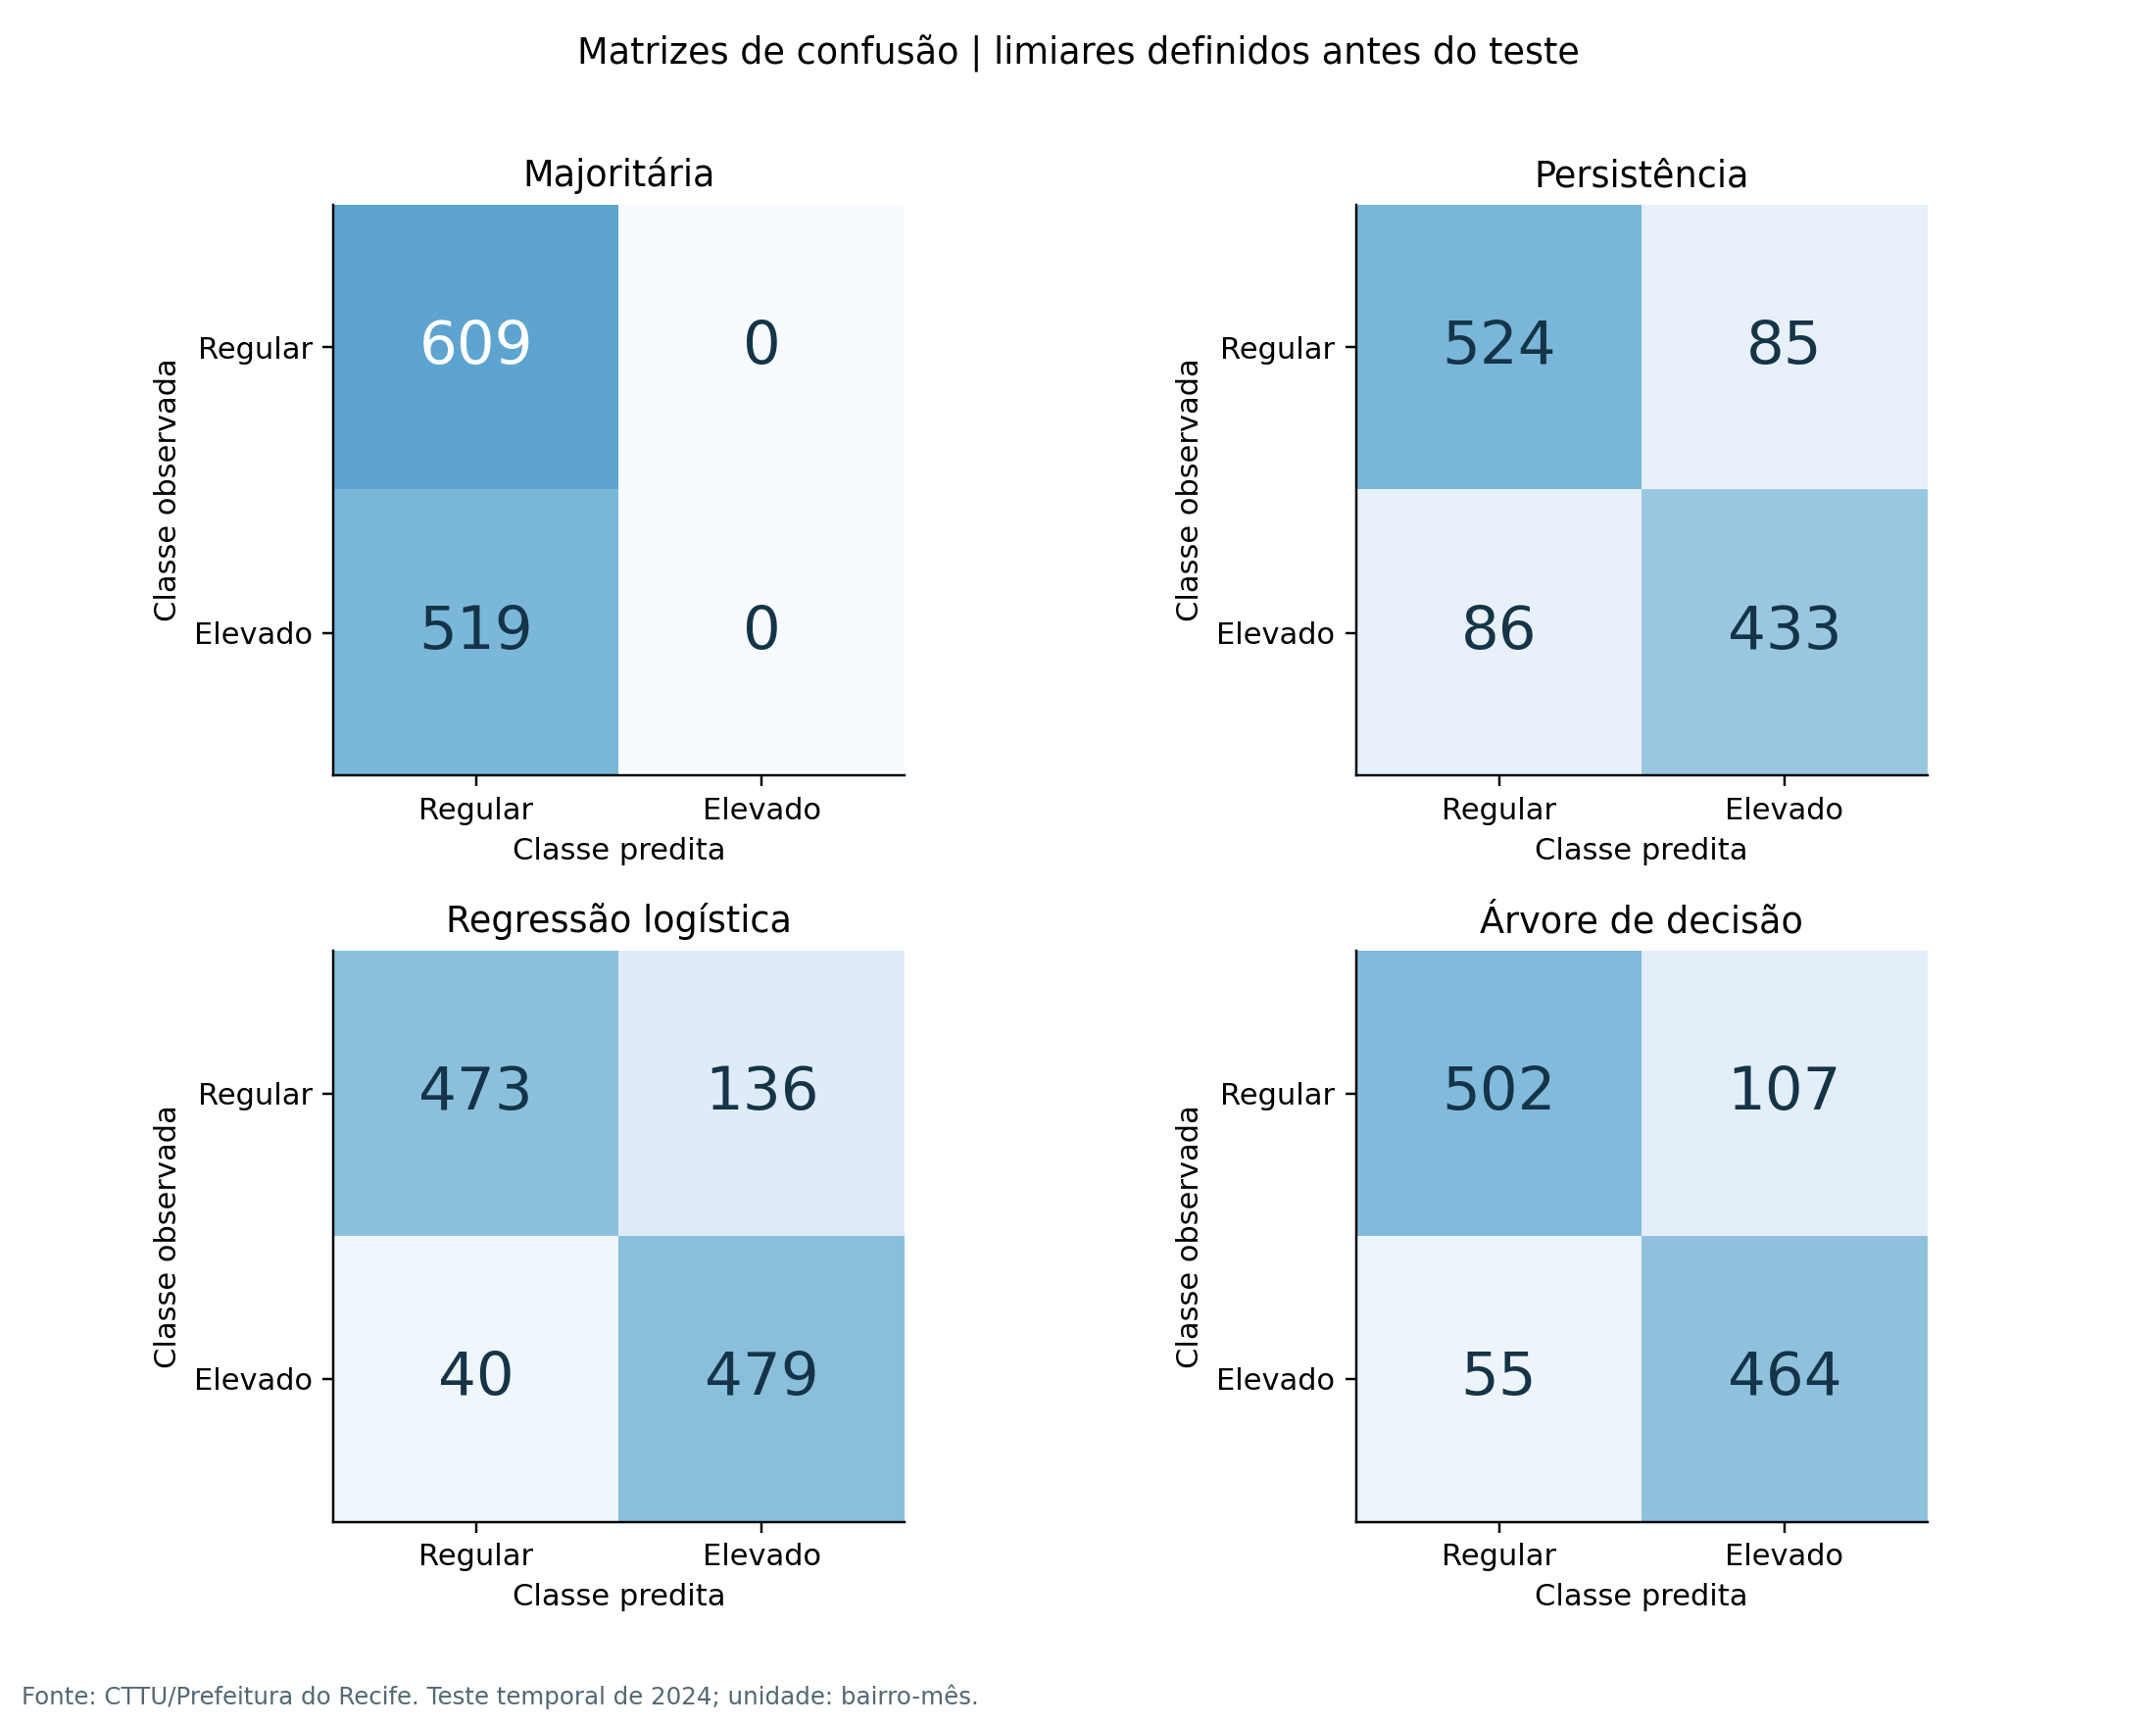

### 02 curvas roc

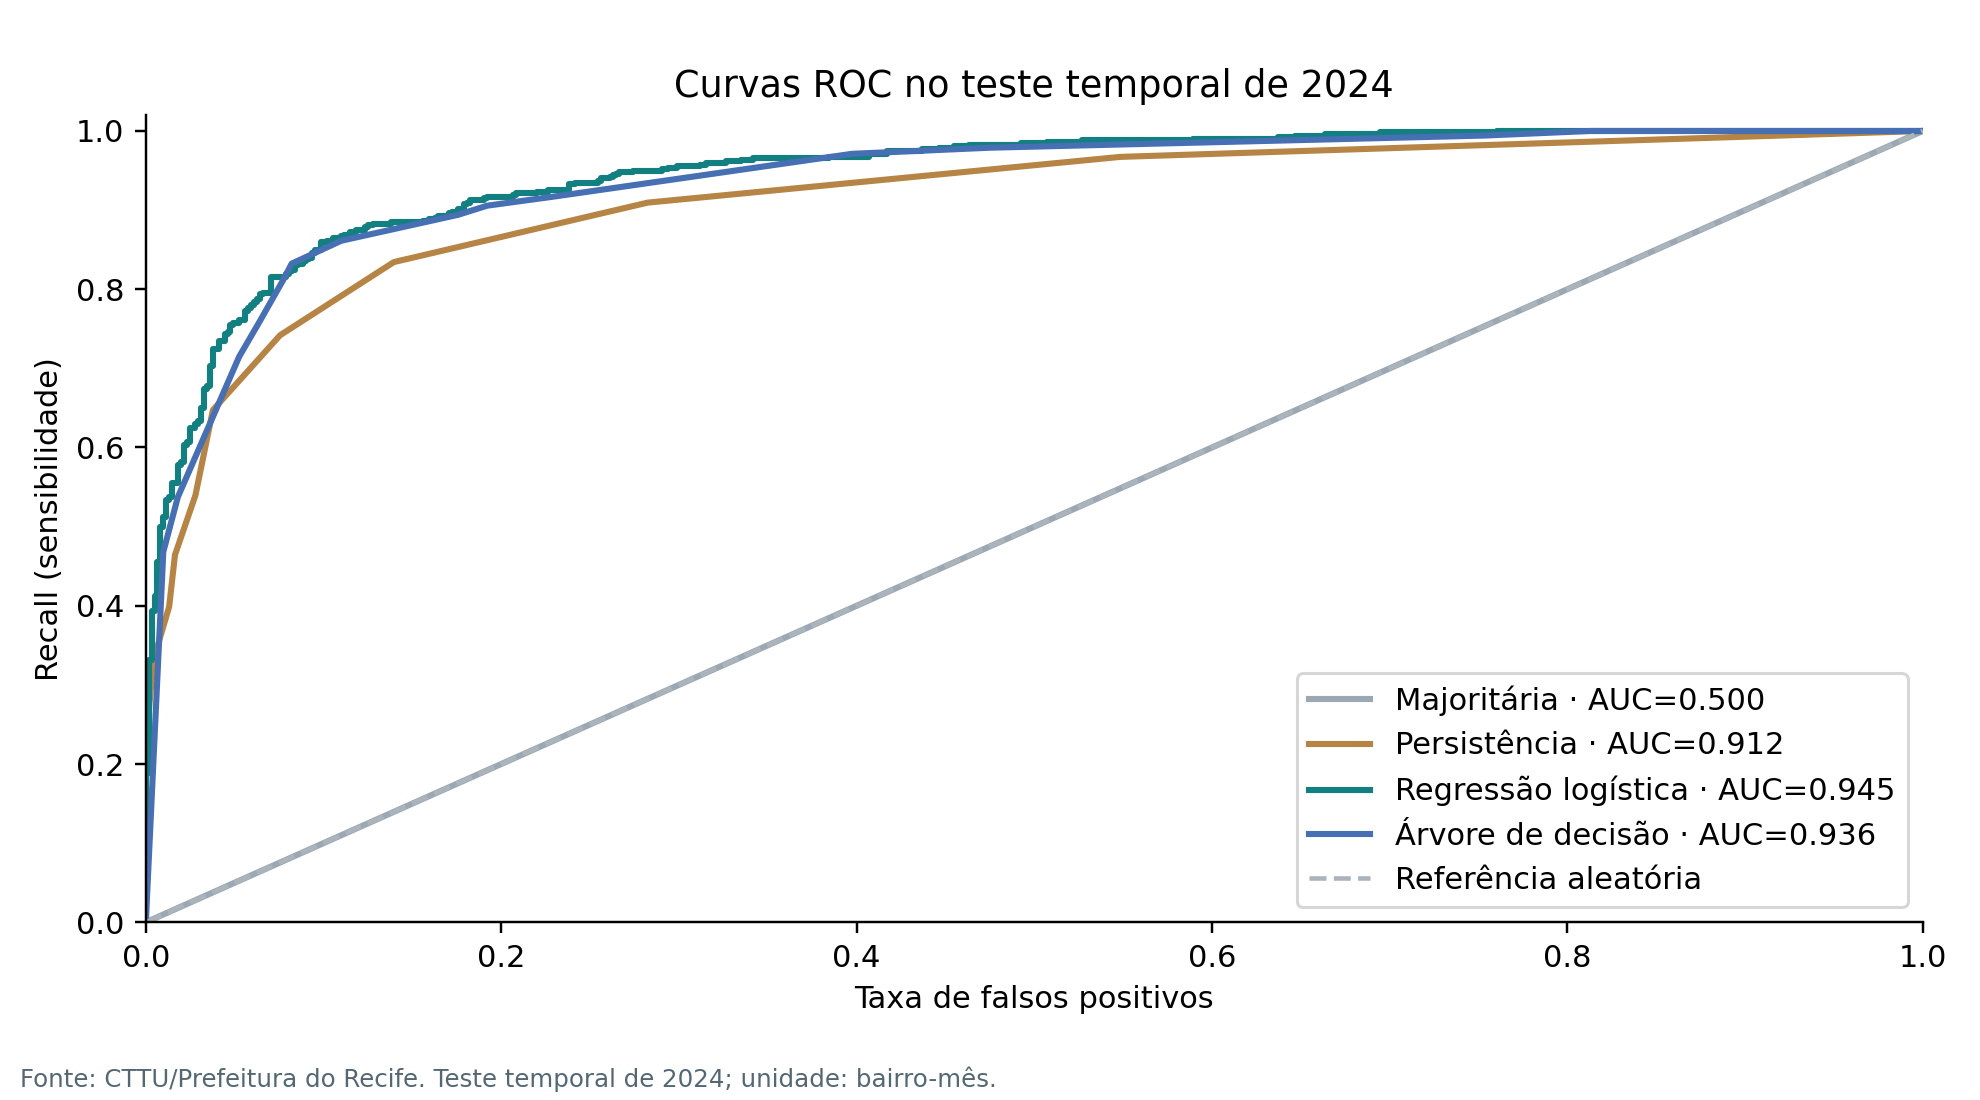

### 03 curvas precision recall

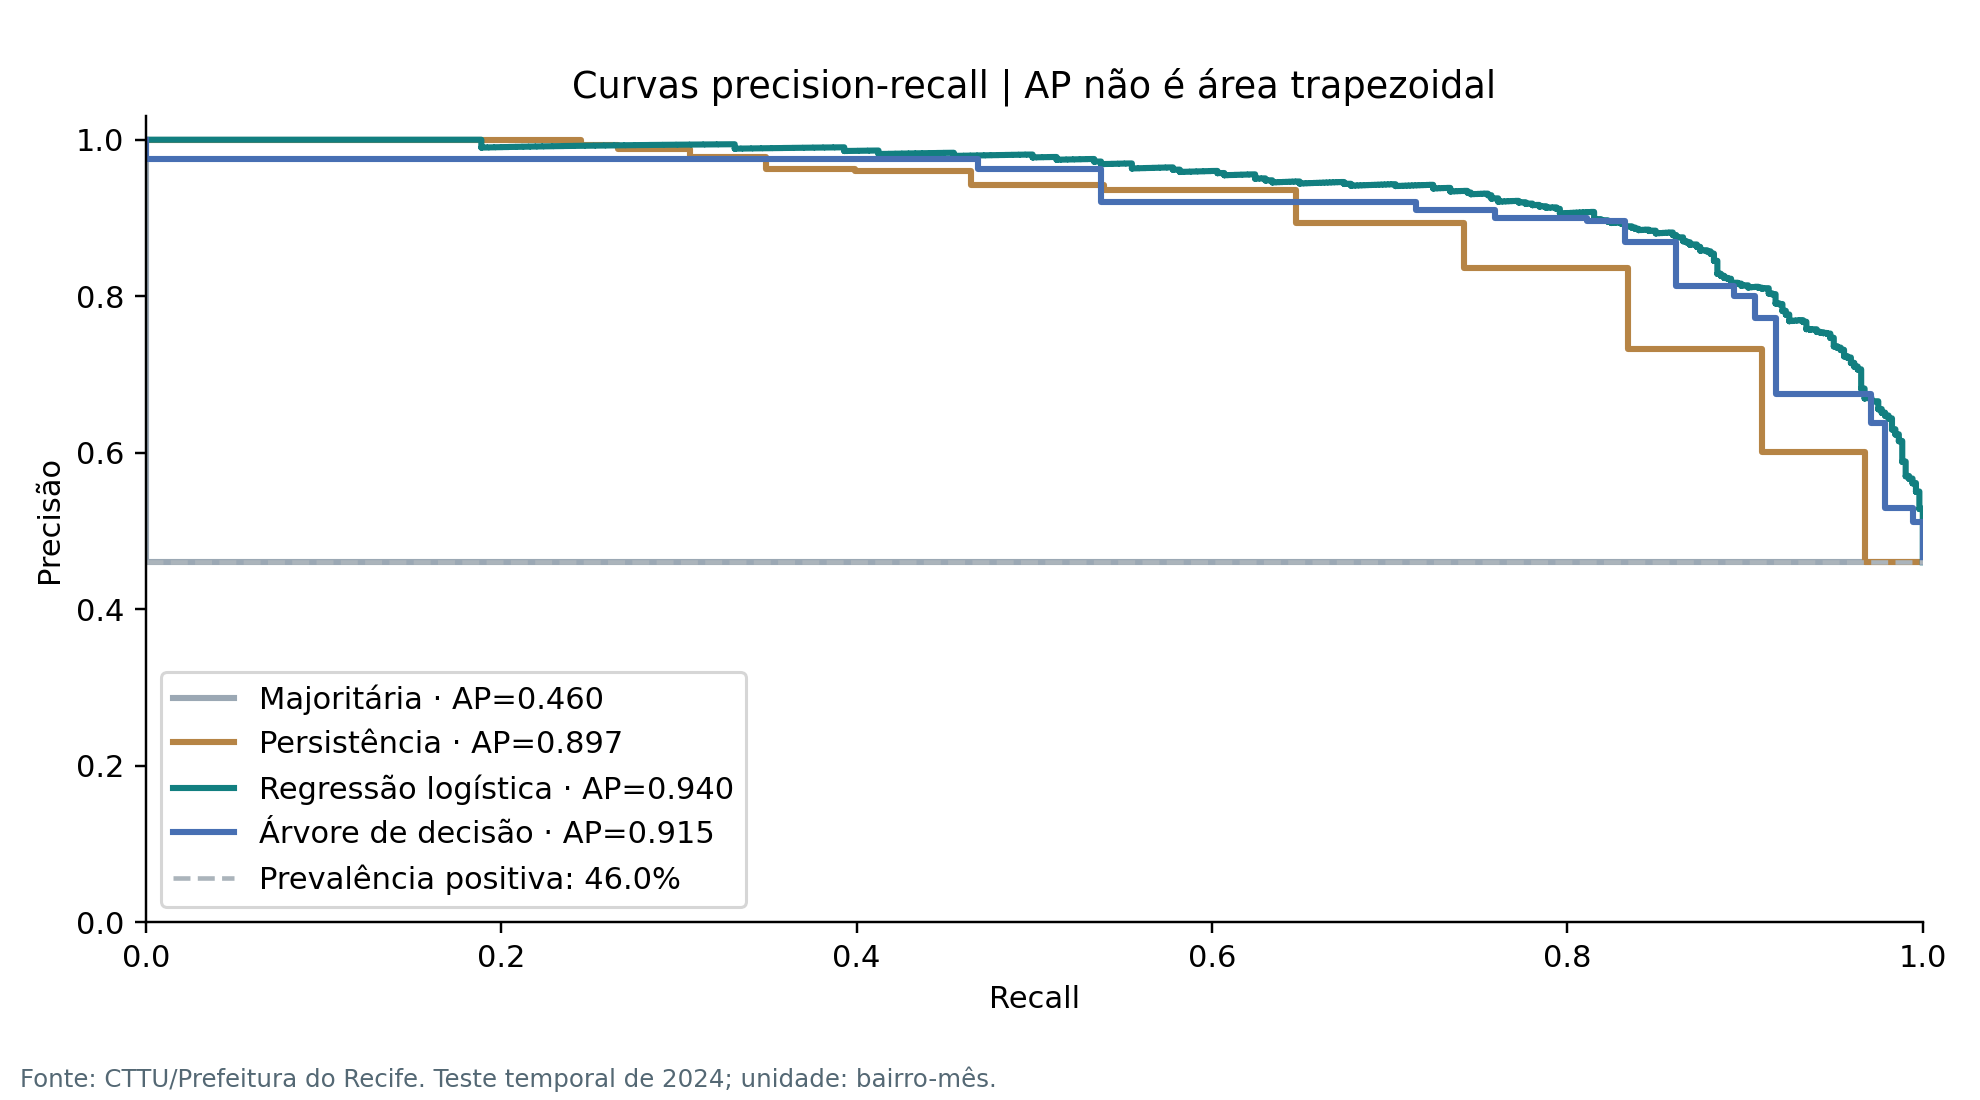

### 04 comparacao metricas

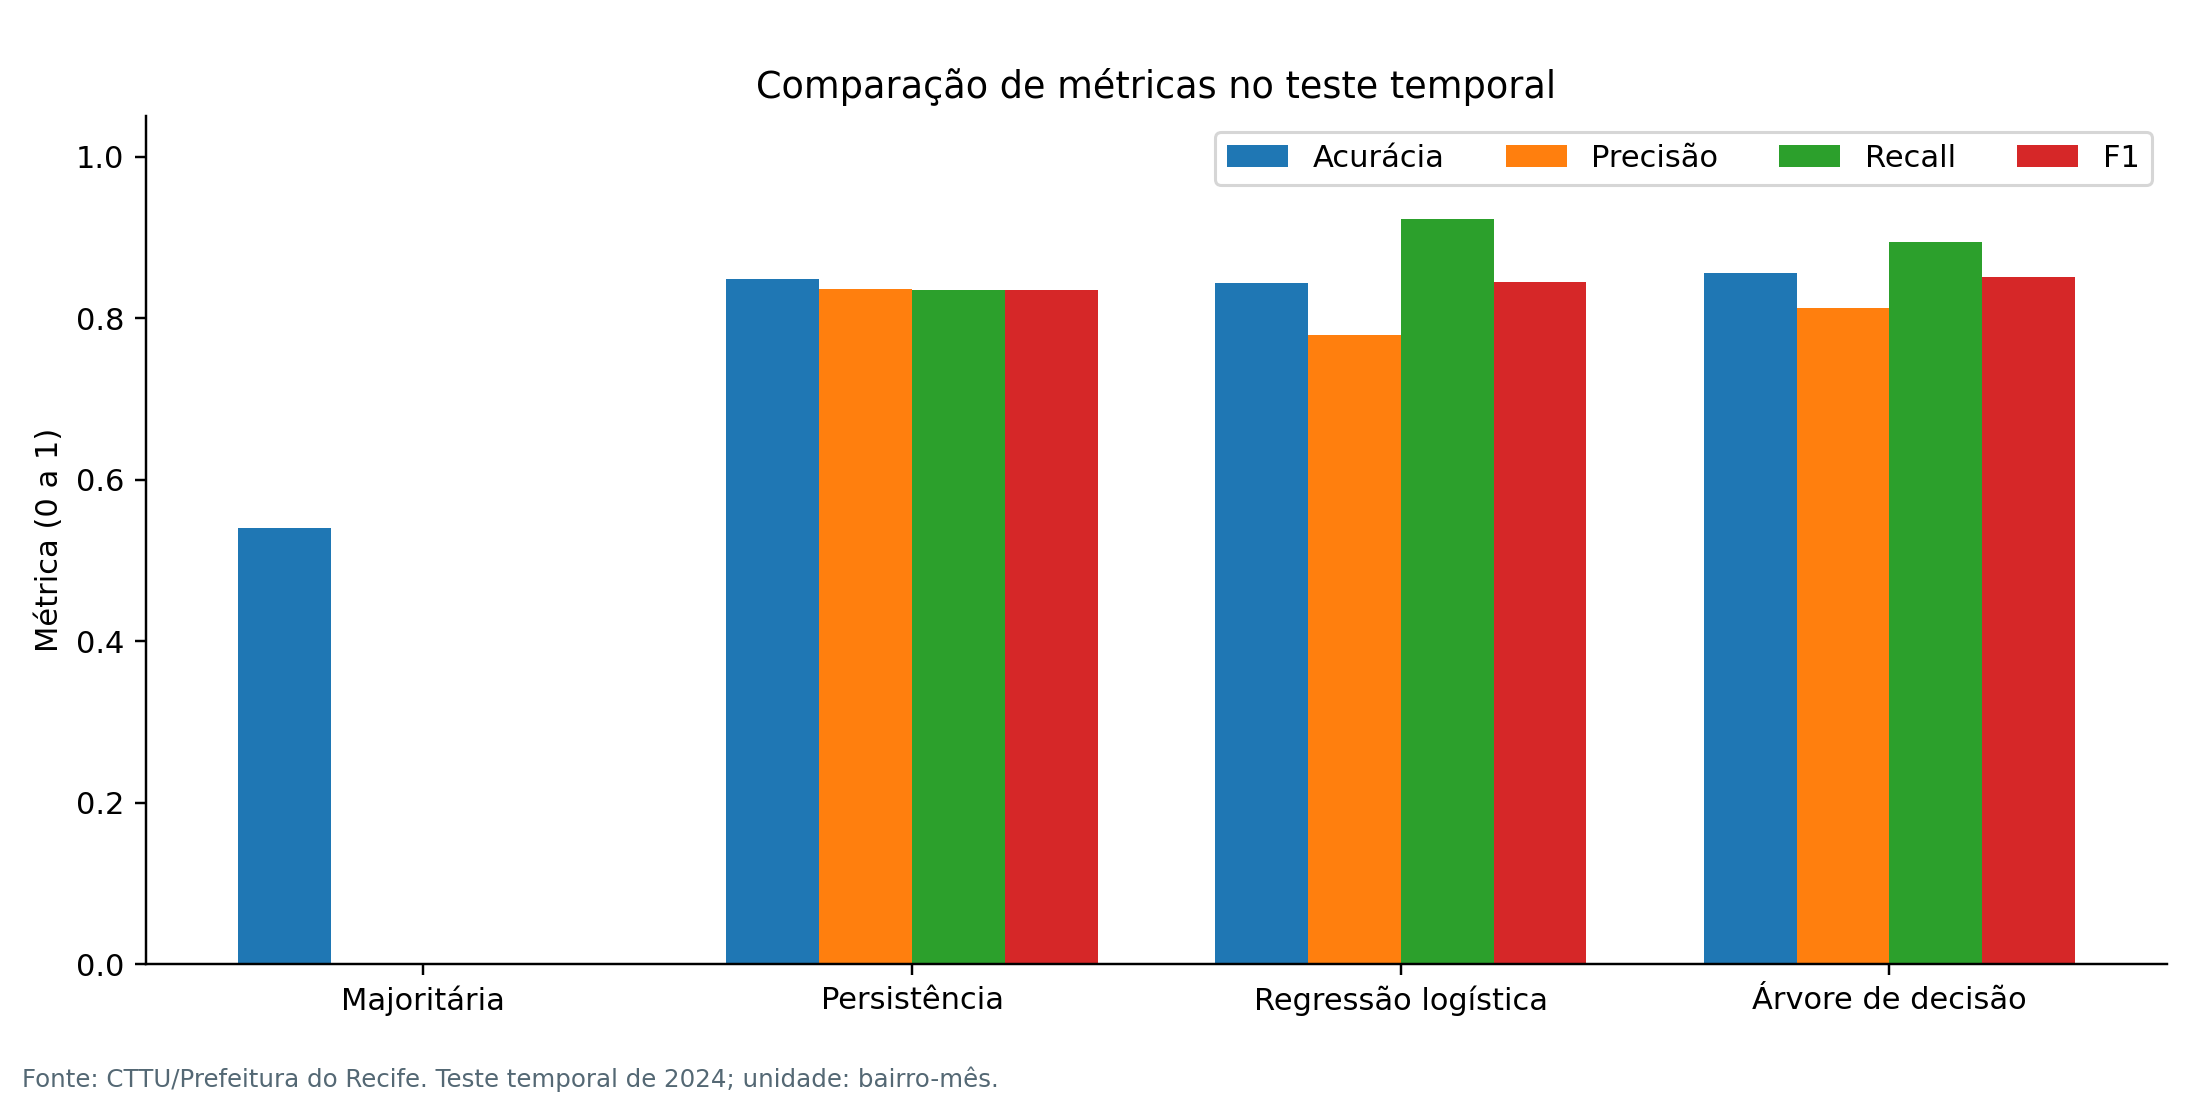

### 05 limiares validacao

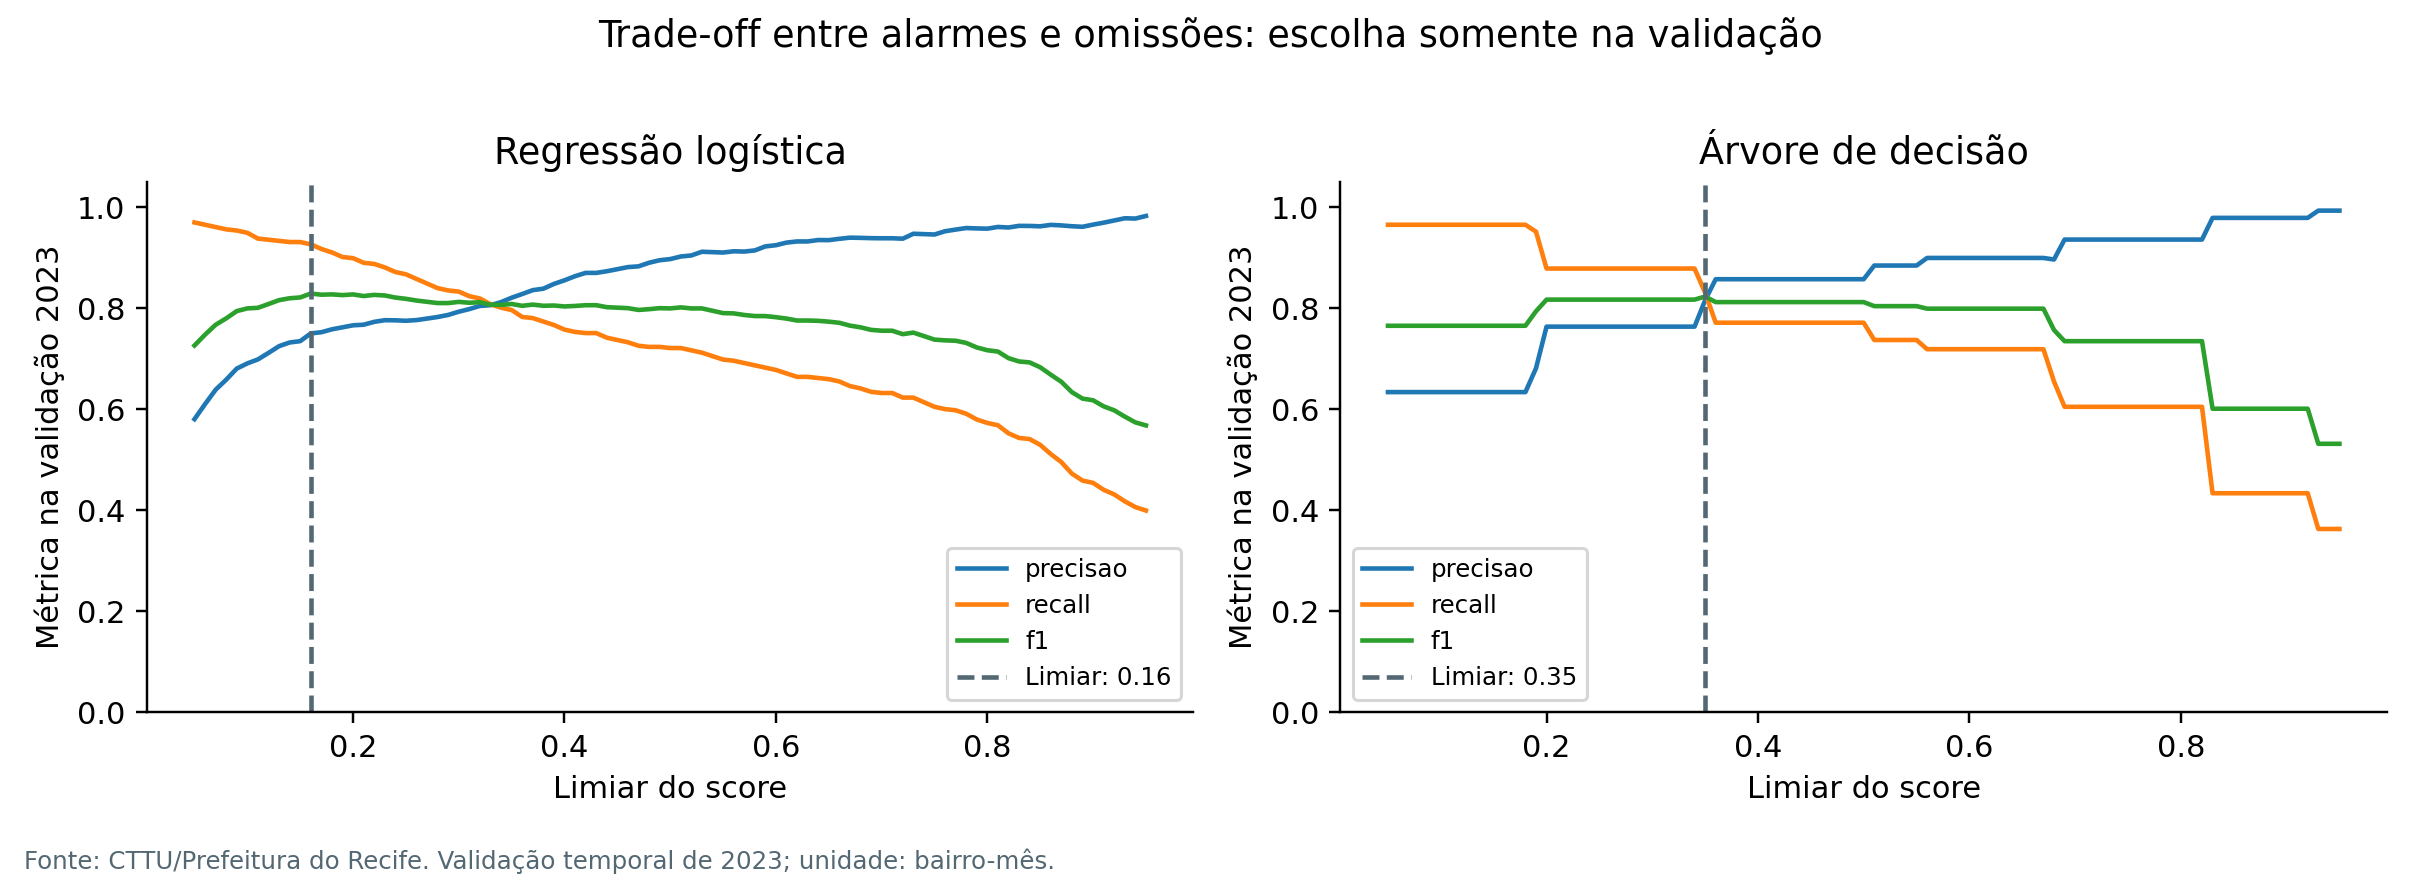

### 06 f1 mensal

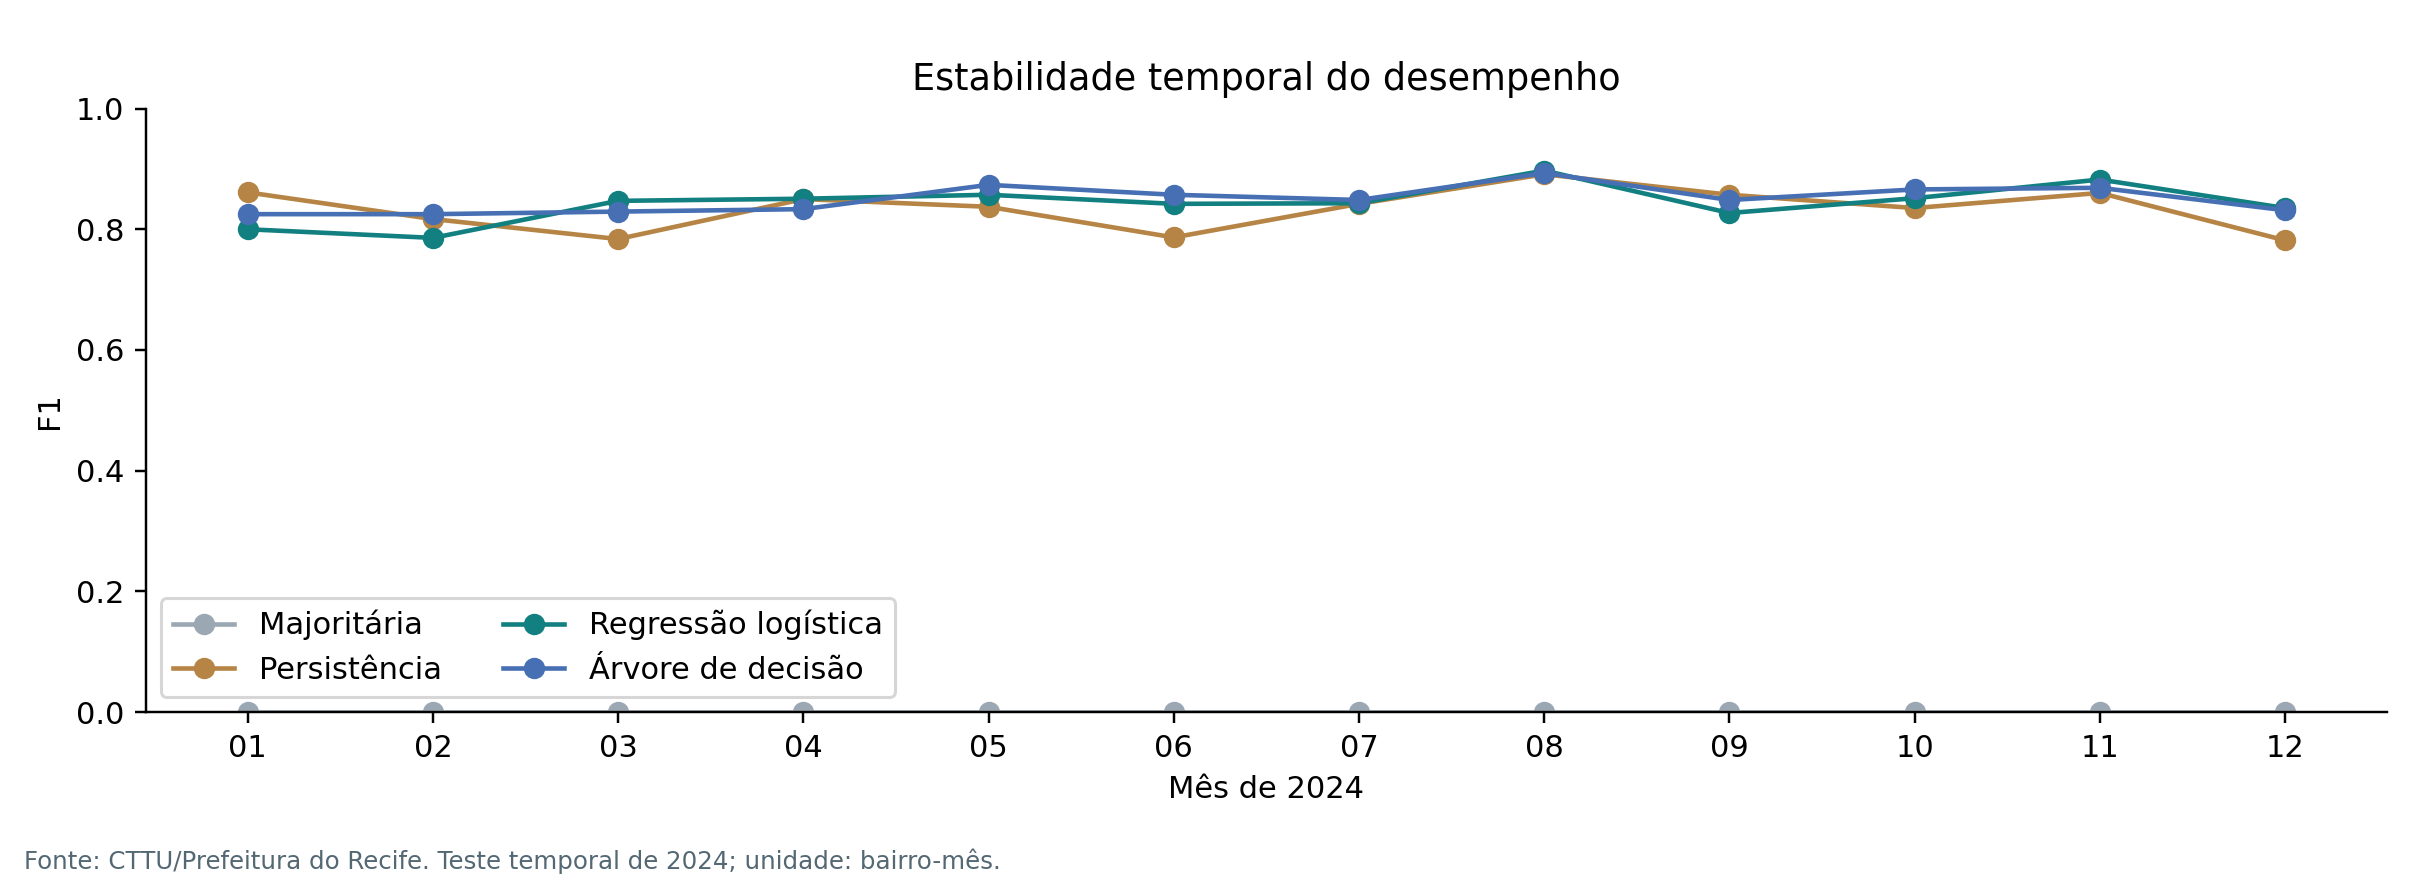

### 07 arvore interpretavel

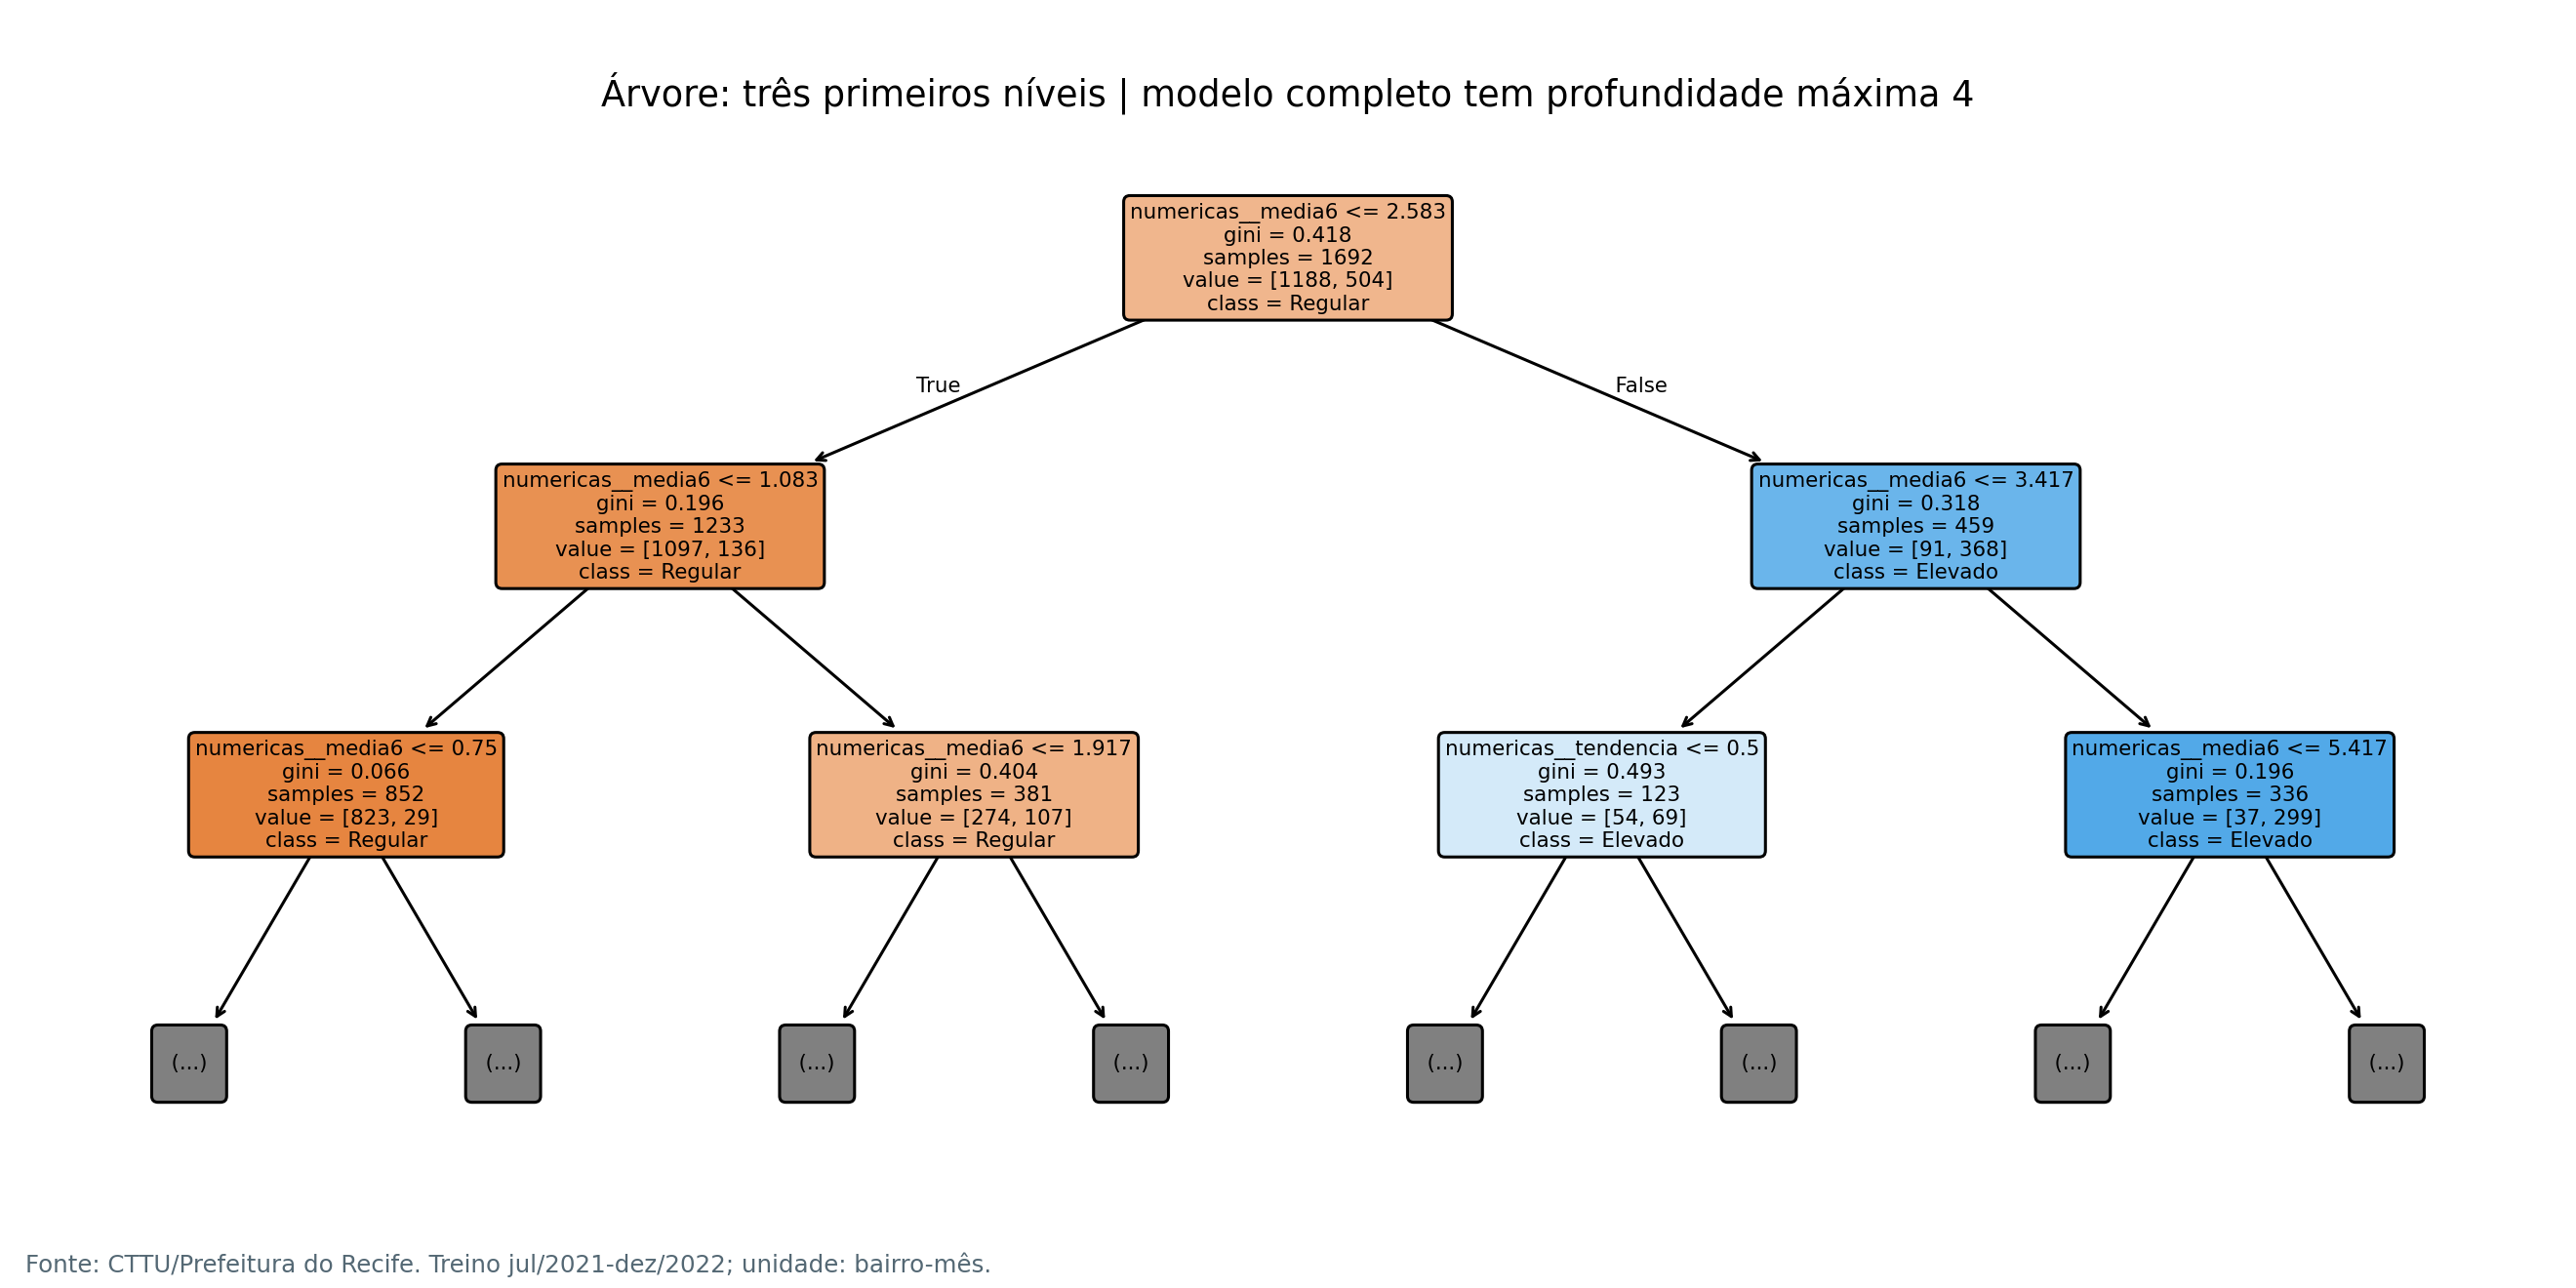

### 08 erros bairro

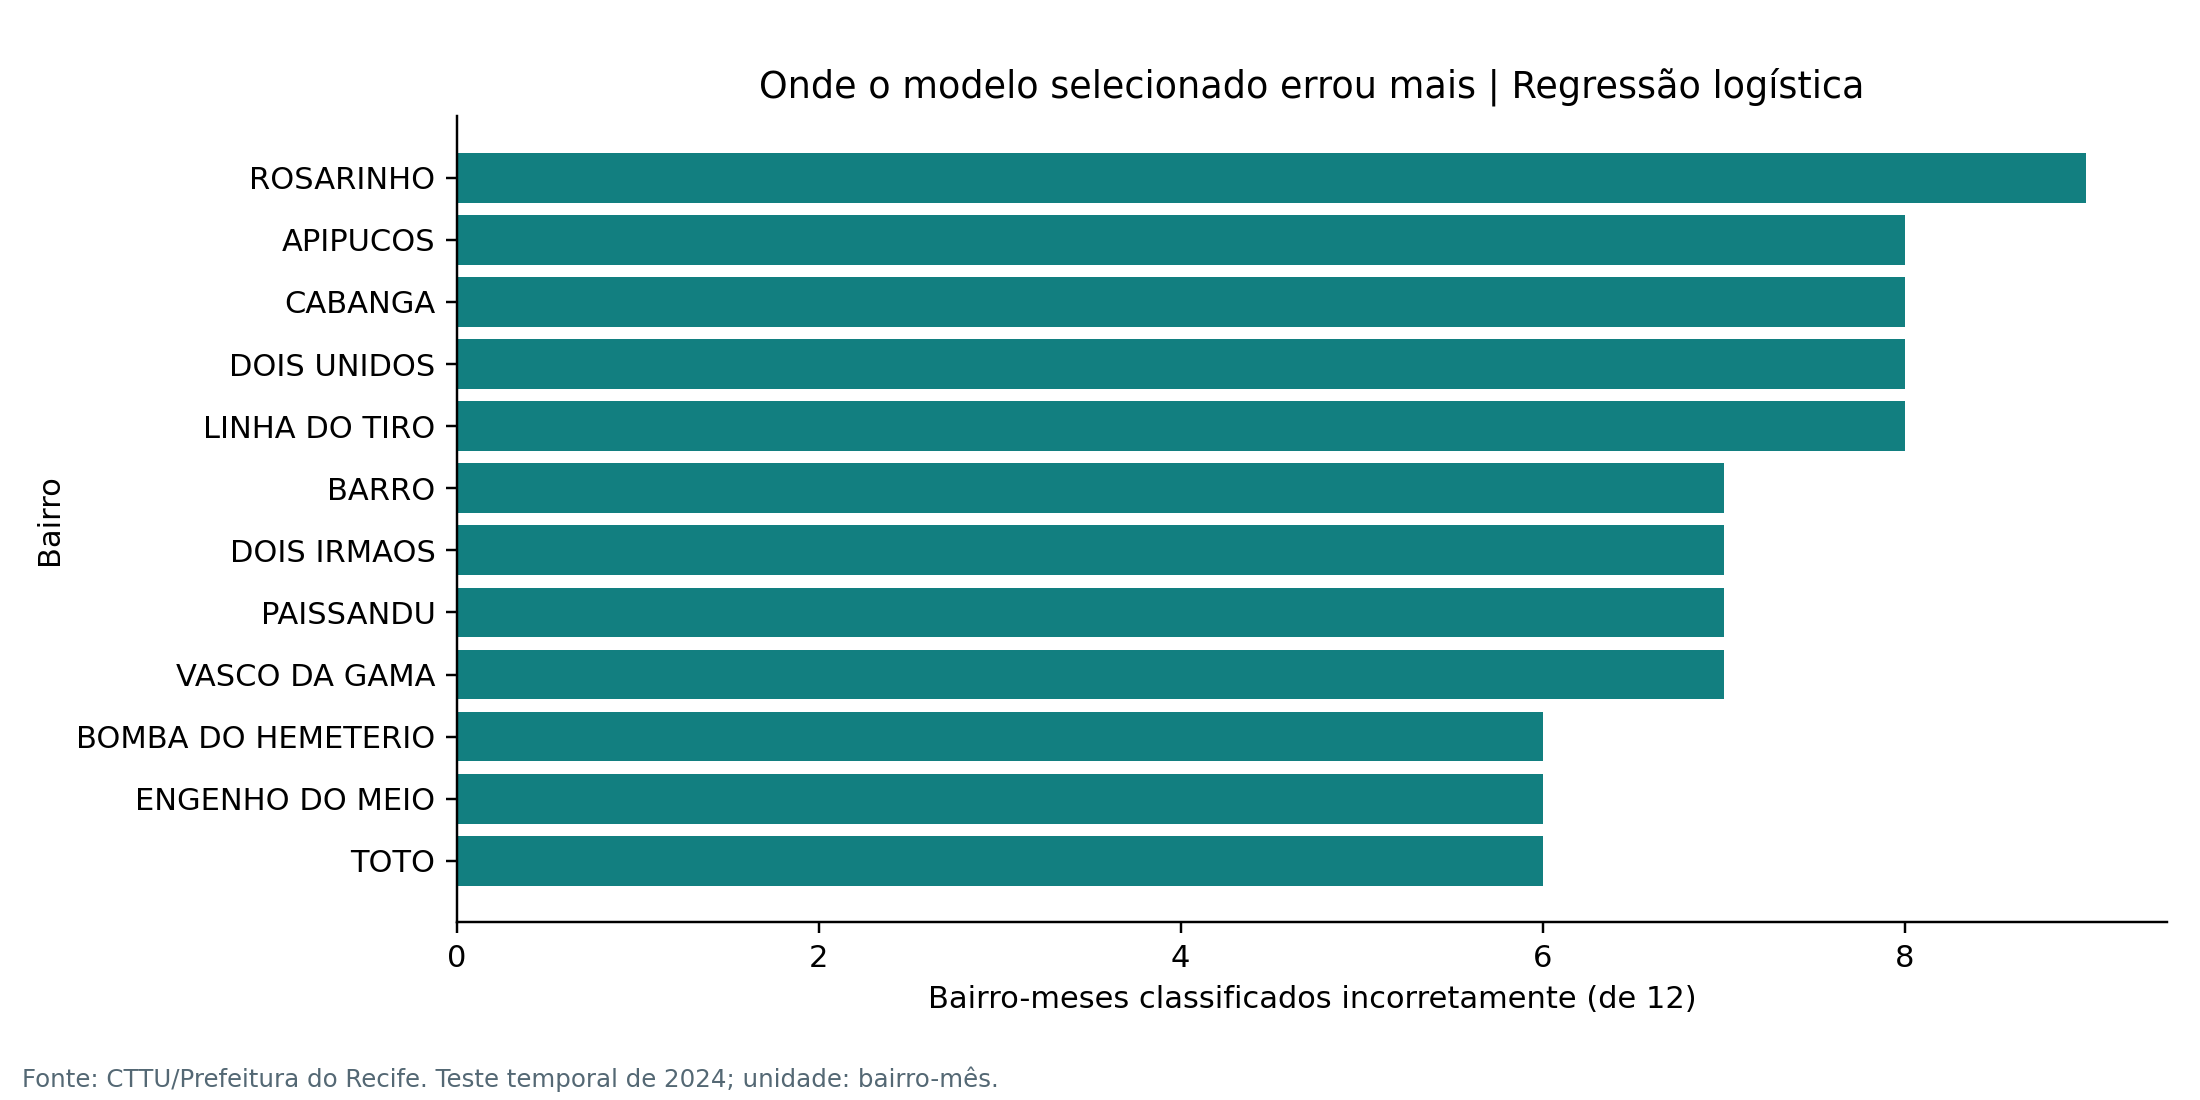

In [12]:
figuras(metricas,predicoes,metodo,modelos,SAIDA)
for f in sorted((SAIDA/'graficos').glob('*.png')):
    display(Markdown('### '+f.stem.replace('_',' ')))
    display(Image(filename=str(f),width=1000))

## 6. Interpretação dos resultados e implicações práticas
A seleção deve permanecer vinculada à validação, mesmo se outro modelo tiver melhor métrica pontual no teste. Compare ganhos com a persistência, e não apenas com a majoritária. O custo de um falso alerta é investigar um bairro-mês que não atingiu o corte; o de uma omissão é deixar um bairro-mês elevado sem priorização.

O ganho de recall pode exigir mais alertas falsos. A interpretação é sobre volume de chamados sob o processo de registro disponível, sem concluir redução causal de sinistros. O corte de 3 chamados é relativo ao período de treino e não um parâmetro oficial de segurança viária.

In [13]:
z=metricas[(metricas.particao=='teste')&(metricas.modelo==metodo['modelo_selecionado'])].iloc[0]
b=metricas[(metricas.particao=='teste')&(metricas.modelo=='persistencia')].iloc[0]
texto=f"""Modelo selecionado: {z['nome']}; limiar {z['limiar']:.2f}.
No teste: acurácia {z['acuracia']:.2%}, precisão {z['precisao']:.2%}, recall {z['recall']:.2%}, F1 {z['f1']:.4f}.
ROC AUC {z['roc_auc']:.4f}; AP {z['average_precision']:.4f}.
Matriz: VN={int(z['tn'])}, FP={int(z['fp'])}, FN={int(z['fn'])}, VP={int(z['tp'])}.
Contra a persistência: {int(b['fn']-z['fn'])} omissões a menos e {int(z['fp']-b['fp'])} falsos alertas a mais.
F1 da persistência={b['f1']:.4f}; ganho absoluto={z['f1']-b['f1']:.4f}. A acurácia da persistência={b['acuracia']:.2%}.
A árvore teve F1 pontual superior no teste, mas não foi escolhida a posteriori.
Não há validação operacional, causal ou de risco individual."""
print(texto)
(SAIDA/'interpretacao_resultados.txt').write_text(texto,encoding='utf-8')
# Sensibilidade descritiva: dezembro/2024 termina em 28/12 no arquivo.
linhas=[]
for nome,g in predicoes[(predicoes.particao=='teste')&(predicoes.periodo<'2024-12')].groupby('modelo'):
    linhas.append({'modelo':nome,**metrics(g.alvo,g.score,metodo['limiares'][nome])})
pd.DataFrame(linhas).to_csv(SAIDA/'tabelas/sensibilidade_sem_dezembro_2024.csv',index=False)
display(pd.DataFrame(linhas))

Modelo selecionado: Regressão logística; limiar 0.16.
No teste: acurácia 84.40%, precisão 77.89%, recall 92.29%, F1 0.8448.
ROC AUC 0.9447; AP 0.9400.
Matriz: VN=473, FP=136, FN=40, VP=479.
Contra a persistência: 46 omissões a menos e 51 falsos alertas a mais.
F1 da persistência=0.8351; ganho absoluto=0.0097. A acurácia da persistência=84.84%.
A árvore teve F1 pontual superior no teste, mas não foi escolhida a posteriori.
Não há validação operacional, causal ou de risco individual.


,modelo,acuracia,precisao,recall,f1,acuracia_balanceada,roc_auc,average_precision,tn,fp,fn,tp,n,positivos,limiar
0,arvore,0.857834,0.821154,0.887734,0.853147,0.859780,0.936773,0.918252,460,93,54,427,1034,481,0.35
1,dummy,0.534816,0.000000,0.000000,0.000000,0.500000,0.500000,0.465184,553,0,481,0,1034,481,0.50
2,logistica,0.844294,0.784698,0.916840,0.845638,0.849017,0.945634,0.942757,432,121,40,441,1034,481,0.16
3,persistencia,0.852998,0.850746,0.829522,0.840000,0.851470,0.914107,0.900107,483,70,82,399,1034,481,0.50


## 7. Dados do dashboard e verificação de consistência
A interface usa um snapshot sem endereço e sem protocolo. Os sete campos históricos são ano, mês, dia da semana, hora, índice de bairro, índice de tipo e índice de situação. O significado das categorias não é unificado entre anos. Ao selecionar todos os anos, o gráfico de tipos pede um ano específico.

Os filtros históricos são independentes da avaliação de 2024. O slider de limiar permite explorar custos no teste, mas não altera a tabela oficial de métricas nem redefine o modelo selecionado. O dashboard HTML entregue já inclui os dados; abre offline sem instalar dependências.

In [14]:
def export_dashboard(base,bairros,quality,result,preds,meta,root):
    root=Path(root);d=root/'semana_2_dashboard';d.mkdir(exist_ok=True)
    valid=base.loc[base.data_valida].copy();valid['ano']=valid.data_dt.dt.year;valid['mes']=valid.data_dt.dt.month;valid['semana']=valid.data_dt.dt.dayofweek
    # Apenas os campos agregáveis são publicados. Endereços, nomes livres e protocolos ficam fora da interface.
    bidx={b:i for i,b in enumerate(bairros)};types=sorted(base.tipo_chave.dropna().unique().tolist());statuses=sorted(base.situacao_chave.dropna().unique().tolist())
    ti={t:i for i,t in enumerate(types)};si={s:i for i,s in enumerate(statuses)}
    rows=[]
    for r in valid.itertuples():rows.append([int(r.ano),int(r.mes),int(r.semana),int(r.hora_n) if pd.notna(r.hora_n) else -1,bidx.get(r.bairro_chave,-1) if pd.notna(r.bairro_chave) else -1,ti.get(r.tipo_chave,-1) if pd.notna(r.tipo_chave) else -1,si.get(r.situacao_chave,-1) if pd.notna(r.situacao_chave) else -1])
    rawgeo=json.loads((root/'dados/brutos/bairros_oficiais.geojson').read_text());geo=[]
    for f in rawgeo['features']:
        key=prep.chave(f['properties']['EBAIRRNOME'])
        if key not in bidx:raise ValueError('Malha e relação oficial de bairros divergentes: '+key)
        geom=f['geometry'];polys=geom['coordinates'] if geom['type']=='MultiPolygon' else [geom['coordinates']]
        # Simplificação para visualização, sem atribuir coordenadas pontuais aos chamados.
        rings=[]
        for poly in polys:
            for ring in poly:
                step=max(1,len(ring)//180);pts=ring[::step]
                if pts[-1]!=pts[0]:pts.append(pts[0])
                rings.append([[round(x,6),round(y,6)] for x,y,*_ in pts])
        geo.append({'i':bidx[key],'rings':rings})
    predictions={}
    for name,g in preds[preds.particao.eq('teste')].groupby('modelo'):
        predictions[name]=[[bidx[r.bairro],r.periodo,int(r.chamados),int(r.alvo),float(r.score)] for r in g.itertuples()]
    curves={}
    for name,g in preds[preds.particao.eq('teste')].groupby('modelo'):
        fpr,tpr,_=roc_curve(g.alvo,g.score);p,r,_=precision_recall_curve(g.alvo,g.score)
        curves[name]={'roc':[[round(float(x),6),round(float(y),6)] for x,y in zip(fpr,tpr)],'pr':[[round(float(x),6),round(float(y),6)] for x,y in zip(r,p)]}
    metricsjson=json.loads(result[result.particao.eq('teste')].to_json(orient='records'))
    obj={'meta':meta,'bairro':bairros,'tipo':types,'situacao':statuses,'records':rows,'geo':geo,
        'predictions':predictions,'curves':curves,'metrics':metricsjson,
        'quality':json.loads(quality.to_json(orient='records')),'totais':{'brutos':len(base),'datados':len(valid),'bairro_validado':int(base.bairro_validado.sum())}}
    dump(d/'dados_dashboard.json',obj)
    return obj



In [15]:
dados_dashboard=export_dashboard(base,bairros,qualidade,metricas,predicoes,metodo,RAIZ)
assert len(dados_dashboard['records'])==int(base.data_valida.sum())
assert all(r.tn+r.fp+r.fn+r.tp==r.n for r in metricas.itertuples())
assert painel.loc[painel.particao.eq('treino'),'periodo'].max()<painel.loc[painel.particao.eq('validacao'),'periodo'].min()
assert painel.loc[painel.particao.eq('validacao'),'periodo'].max()<painel.loc[painel.particao.eq('teste'),'periodo'].min()
print('Verificado: totais, chaves temporais, matrizes e partições.')
print('Dados do dashboard:',RAIZ/'semana_2_dashboard/dados_dashboard.json')

Verificado: totais, chaves temporais, matrizes e partições.
Dados do dashboard: /workspace/scratch/b0cc3dc3bfea/entregas_semanais/semana_2_dashboard/dados_dashboard.json


## Limitações e referências
- 2015 parcial; alteração de captação entre anos; todos os status representam chamados e não acidentes únicos confirmados.
- 36 datas de outro ano no arquivo de 2024; última data válida em 28/12/2024. Meses observados não comprovam cobertura completa. Inclui-se sensibilidade sem dezembro.
- 2022 sem horário utilizável; nomes de bairro sem correspondência exata fora da classificação espacial. Os bairros oficiais sem linhas são zeros no arquivo, sob a hipótese explícita de usar o cadastro inteiro.
- `vitimasfatais` ausente em 2015 e com mais de 99% de ausência em 2016–2020; não usado como alvo ou preditor. O preenchimento de 2021–2024 não garante equivalência histórica.
- Prevalência positiva: 29,8% no treino, 38,8% na validação e 46,0% no teste. Existe mudança da distribuição; um cutoff fixo pode requerer revisão em outro regime.
- Sem validação prospectiva, custos reais, exposição viária, calibração de scores ou efeito causal demonstrado.

Fontes: [CTTU](https://dados.recife.pe.gov.br/dataset/acidentes-de-transito-com-e-sem-vitimas); [Área urbana](https://dados.recife.pe.gov.br/dataset/area-urbana); [métricas scikit-learn](https://scikit-learn.org/stable/modules/model_evaluation.html); [prevenção de vazamento](https://scikit-learn.org/stable/common_pitfalls.html). Os arquivos originais, hashes, scripts, métricas e previsões individuais constam no ZIP da entrega.